# Jupyter Notebook 1. EDA и подготовка данных

**Стажёр:** [введите ваше имя]

На входе — сырые данные из таблиц трёх видов: `listings`, `calendar`, `reviews`.
На выходе вы должны создать датасет для обучения модели.

## 1.Подключение библиотек

In [1]:
%%writefile requirements.txt

# Core Data Science & ML Stack
numpy==1.26.4
pandas==2.2.2
scikit-learn==1.6.1
joblib==1.5.3

# EDA & Analytics
matplotlib==3.8.4
seaborn==0.13.2
phik==0.12.5
numba==0.60.0

# Инфраструктура
boto3==1.34.34
botocore==1.34.34
psycopg2-binary==2.9.9

Writing requirements.txt


In [2]:
#!pip install -r requirements.txt -q

In [3]:
# если не установлена раскомментировать
!pip install phik boto3 psycopg2 python-dotenv -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 3.0 MB/s eta 0:00:00


In [4]:
# для использования кредов из .env
from dotenv import load_dotenv
load_dotenv()

False

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# для работы с PostgreSQL
import psycopg2

#  для проверки корреляции
import phik

# для предобработки текста перед векторизацией
import nltk # импортируем библиотеку nltk для обработки текста
from nltk.corpus import stopwords # импортируем стоп-слова
import re

# для преобразования текстовых данных в числовые векторы на основе метода TF‑IDF
from sklearn.feature_extraction.text import TfidfVectorizer

# для работы с разреженными матрицами (sparse matrices)
import scipy.sparse as sp


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split

import joblib

import json
import os
import boto3
import io

## 2.Загрузка и первичный осмотр данных

Загрузите таблицы. Для каждой зафиксируйте размер, типы данных, пропуски и ключевые наблюдения.

In [6]:
print(load_dotenv())              # False
print(os.getenv("DB_HOST"))       # None

False
None


In [8]:
#  подключение к базе данных PostgreSQL и загрузка данных для анализа
# для .env
conn = psycopg2.connect(
    dbname=os.getenv("DB_NAME"),
    user=os.getenv("DB_USER"),
    password=os.getenv("DB_PASS"),
    host=os.getenv("DB_HOST"),
    port=os.getenv("DB_PORT")
)
# Создаем прямое подключение через psycopg2
#conn = psycopg2.connect(
#    dbname=DB_NAME,
#    user=DB_USER,
#    password=DB_PASS,
#    host=DB_HOST,
#    port=DB_PORT
#)

### listings

#### Объединение всех таблиц Listings по городам в один общий датафрейм

In [9]:
# Список городов, присутствующих в схеме final_project
cities = [
    "amsterdam",
    "chicago",
    "la",
    "london",
    "lyon",
    "munich",
    "nyc",
    "paris",
    "toronto",
    "vienna"
]

In [10]:
# Объединяем все таблицы listings по всем городаи и добавляем колонку city
queries = []
for city in cities:
    q = f"""
    SELECT '{city}' as city,
    CAST(id AS BIGINT) AS id_int,
    *
    FROM final_project.{city}_listings
    """
    queries.append(q)

full_query = "\nUNION ALL\n".join(queries) + ";"

all_listings = pd.read_sql(full_query,conn)
# заменяем неточный float-id на точный int64
all_listings = all_listings.drop(columns='id').rename(columns={'id_int': 'id'})
print(all_listings['id'].dtype)   # должно быть int64
all_listings.head()

/tmp/ipykernel_16287/2416054801.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  all_listings = pd.read_sql(full_query,conn)


int64


,city,id,source,name,description,neighborhood_overview,host_id,host_since,host_response_time,host_response_rate,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,amsterdam,27886,city scrape,"Романтический, стильный плавучий дом типа «пос...",Stylish and romantic houseboat on fantastic hi...,"Central, quiet, safe, clean and beautiful.",97647.0,2010-03-23,within an hour,100%,...,4.95,4.93,4.90,4.78,False,1.0,0.0,1.0,0.0,1.87
1,amsterdam,28871,city scrape,Комфортабельный двухместный номер,Basic bedroom in the center of Amsterdam.,"Flower market , Leidseplein , Rembrantsplein",124245.0,2010-05-13,within an hour,100%,...,4.94,4.94,4.93,4.83,False,2.0,0.0,2.0,0.0,3.99
2,amsterdam,29051,city scrape,Комфортабельный одноместный/двухместный номер,This room can also be rented as a single or a ...,the street is quite lively especially on weeke...,124245.0,2010-05-13,within an hour,100%,...,4.93,4.92,4.87,4.79,False,2.0,0.0,2.0,0.0,4.81
3,amsterdam,44391,previous scrape,Тихая 2-комнатная квартира в центре Амстердама,Guests greatly appreciate the unique location ...,The appartment is located in the city centre. ...,194779.0,2010-08-08,None,None,...,4.95,4.90,4.68,4.50,False,1.0,1.0,0.0,0.0,0.23
4,amsterdam,48373,previous scrape,Уютный семейный дом на юге Амстердама,Charming modern apartment in the quiet and gre...,Apartment is located between Amsterdamse Bos a...,220434.0,2010-09-01,None,None,...,5.00,5.00,4.60,5.00,False,1.0,1.0,0.0,0.0,0.19


In [11]:
all_listings.shape

(661425, 65)

In [12]:
all_listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 661425 entries, 0 to 661424
Data columns (total 65 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   city                                          661425 non-null  object 
 1   id                                            661425 non-null  int64  
 2   source                                        661425 non-null  object 
 3   name                                          661421 non-null  object 
 4   description                                   642000 non-null  object 
 5   neighborhood_overview                         260099 non-null  object 
 6   host_id                                       661425 non-null  float64
 7   host_since                                    571958 non-null  object 
 8   host_response_time                            386411 non-null  object 
 9   host_response_rate                            38

##### Дубликаты в listings

In [13]:
# проверяем наличие дубликатов по listing_id
all_listings.duplicated(subset="id").sum()

np.int64(297341)

In [14]:
# удаляем дубликаты
# Оставляем одну строку на объявление, ключ - (city, id).
n_before = len(all_listings)
all_listings = all_listings.drop_duplicates(subset=['city', 'id'], keep='first').reset_index(drop=True)
print(f"Было: {n_before}, стало: {len(all_listings)}, удалено: {n_before - len(all_listings)}")

Было: 661425, стало: 364084, удалено: 297341


In [15]:
# преобразуем тип колонки price из object в float с удалением текстовых символов
all_listings['price'] = all_listings['price'].str.replace('$', '').str.replace(',', '').astype(float)

In [16]:
# проверяем наличие пропусков
with pd.option_context("display.max_rows", None):
    print(all_listings.isna().sum())

city                                                 0
id                                                   0
source                                               0
name                                                 2
description                                      10307
neighborhood_overview                           226736
host_id                                              0
host_since                                       53677
host_response_time                              152031
host_response_rate                              152031
host_acceptance_rate                            136097
host_is_superhost                                 6920
host_listings_count                               1268
host_total_listings_count                        53677
host_verifications                               53677
host_has_profile_pic                              1270
host_identity_verified                            1268
neighbourhood_cleansed                               0
neighbourh

#### 1. Столбцы для формирования Target (`is_high_demand`)

Эти столбцы нужны **исключительно** для расчета целевой переменной. После того как таргет сформирован, их **обязательно нужно удалить из обучающей матрицы**, чтобы избежать Data Leakage (утечки данных):

* `price` — для расчета медиан цен.
* `numeric_of_reviews_ltm` — для оценки частоты бронирований/отзывов.
* `review_scores_rating` — для учета качества жилья при разметке востребованности.

---

#### 2. Столбцы для генерации новых признаков (Feature Engineering)

Из этих полей мы извлекаем максимальную пользу, создавая вторичные признаки, после чего сырые исходники (особенно даты и тексты) отбрасываем:

| Исходный столбец | Что из него генерируем (Новый признак) |
| --- | --- |
| `last_review`, `first_review` | `days_since_last_review`, `listing_age_days`, `lifecycle_status` (new/active/stale) |

---

#### 3. Финальный список столбцов для обучения моделей (Random Forest, LightGBM, CatBoost)

После генерации новых фичей и отсечения идентификаторов/сырых дат мы оставляем следующий набор данных для обучения:

#### А. Свойства самого объекта (Property & Capacity)

* `city` *(категориальный)*
* `room_type` *(категориальный)*
* `property_type` *(категориальный)*
* `accommodates` *(числовой: вместимость)*
* `bedrooms` *(числовой)*
* `beds` *(числовой)*
* `latitude` *(числовой)*
* `longitude` *(числовой)*
* `neighbourhood_cleansed` *(текстовый)*
* `bathrooms_text` *(текстовый)*
* `amenities` *(текстовый)*
* `name` *(текстовый)*


#### Б. Ограничения и настройки бронирования (Rules & Calendar Settings)

* `minimum_nights` *(числовой)*
* `maximum_nights` *(числовой)*
* `instant_bookable` *(категориальный/бинарный)*
* `availability_eoy` *(числовой)*
* `minimum_nights_avg_ntm` *(числовой)*

#### В. Профиль и активность хоста (Host Profile)

* `host_is_superhost` *(бинарный)*
* `host_identity_verified` *(бинарный)*
* `host_response_time` *(категориальный)*
* `host_listings_count` *(числовой)*
* `host_since` *(дата)*
* `host_response_rate` *(текстовый)*
* `host_acceptance_rate` *(текстовый)*
* `host_total_listings_count` *(числовой)*
* `host_has_profile_pic` *(бинарный)*
* `calculated_host_listings_count` *(числовой)*
* `calculated_host_listings_count_entire_homes` *(числовой)*
* `calculated_host_listings_count_private_rooms` *(числовой)*

#### Г. Признаки Жизненного Цикла и Относительных Метрик (Сгенерированные)

* `days_since_last_review` *(числовой)*
* `listing_age_days` *(числовой)*
* `lifecycle_status` *(категориальный: new, active, stale, no_reviews)*

---

### Столбцы, которые исключаются из обучения:

1. **Идентификаторы:** `id`, `listing_id`, `host_id`, `source`
2. **Сырые тексты и ссылки:** `description`, `neighborhood_overview`.
3. **Сырые столбцы дат:** `host_since`, `first_review`, `last_review`.
4. **Компоненты таргета (во избежание утечки):** `price`, `reviews_per_month`, `numeric_of_reviews_ltm`, `review_scores_rating` (и прочие `review_scores_*`).

##### Пропуски в all_listings

In [17]:
listings_features = [
    'city',
    'id',
    'room_type',
    'property_type',
    'numeric_of_reviews_ltm',
    'price',
    'review_scores_rating',
    'first_review',
    'last_review',
    'host_response_time',
    'host_is_superhost',
    'host_listings_count',
    'host_identity_verified',
    'minimum_nights',
    'maximum_nights',
    'instant_bookable',
    'availability_eoy',
    'accommodates',
    'bedrooms',
    'beds',
    'bathrooms',
    'latitude',
    'longitude',
    'neighbourhood_cleansed',
    'host_since',
    'host_response_rate',
    'host_acceptance_rate',
    'host_total_listings_count',
    'host_has_profile_pic',
    'calculated_host_listings_count',
    'calculated_host_listings_count_entire_homes',
    'calculated_host_listings_count_private_rooms',
    'bathrooms_text',
    'amenities',
    'name',
    'minimum_nights_avg_ntm',
]

In [18]:
df_listings_features = all_listings[listings_features].copy()
df_listings_features.isna().sum()

,0
city,0
id,0
room_type,0
property_type,0
numeric_of_reviews_ltm,0
price,221026
review_scores_rating,87981
first_review,87981
last_review,87981
host_response_time,152031


In [19]:
df_listings_features.shape

(364084, 36)

### **calendars**

##### Объединение всех таблиц calendars

In [20]:
# ЗАКОММЕНТИРОВАЛА, т.к. выгрузка длится очень долго, ниже выгрузку оптимизированную оставила

# Формируем SQL-запрос для всех городов с UNION ALL
# агрегируем данные по listing_id
#calendar_queries = []

#for city in cities:
#    query = f"""
#    SELECT
#       '{city}' AS city,
#        listing_id,
#        AVG(CASE WHEN available = TRUE THEN 1 ELSE 0 END) AS calendar_availability_rate,
#        AVG(CAST(REPLACE(REPLACE(price, '$', ''), ',', '') AS NUMERIC)) AS avg_price,
#        AVG(CAST(REPLACE(REPLACE(adjusted_price, '$', ''), ',', '') AS NUMERIC)) AS avg_adjusted_price,
#        SUM(CASE WHEN available = TRUE THEN 1 ELSE 0 END) AS calendar_booked_days_365,
#        AVG(minimum_nights) AS calendar_avg_min_nights,
#        AVG(maximum_nights) AS calendar_avg_max_nights,
#        MIN(date) AS calendar_min_date,
#        MAX(date) AS calendar_max_date
#    FROM final_project.{city}_calendars
#    GROUP BY listing_id
#    """
#    calendar_queries.append(query)
#
# Объединяем все запросы через UNION ALL
#full_calendar_query = "\nUNION ALL\n".join(calendar_queries) + ";"
#
#try:
#    all_calendars = pd.read_sql(full_calendar_query, con=conn)
#    print(
#        f"Успешно загружены агрегаты календаря! Размерность: {all_calendars.shape}"
#    )
#except Exception as e:
#    print(f"Возникла ошибка при загрузке таблиц calendar из БД:\n{e}")

In [21]:
#all_calendars.head()

In [22]:
#all_calendars.shape

1. Столбцы, которые нельзя использовать в обучении:

* `calendar_booked_days_365` — может привести к утечке данных, т.к. это фактическая суммарная забронированность жилья на 365 дней вперед. Если передать модель количество забронированных дней из будущего, она напрямую увидит факт спроса, а не будет его прогнозировать.

* `avg_price`, `avg_adjusted_price` — В выгрузке эти столбцы полностью пустые . Кроме того, средняя цена из будущего календаря приводит к утечке таргета (ведь таргет частично зависит от price). В listings уже есть базовая price.

* `calendar_min_date`, `calendar_max_date` — Они одинаковы почти для всех объявлений (диапазон 2025-09-11	- 2027-02-13).

2. Столбцы, которые нужно брать в обучение:
* `calendar_availability_rate` - (Доля доступных дней), показывает: Процент дней, когда хост держит календарь открытым для бронирования (от 0.0 до 1.0).

Отличает хостов, активно сдающих жилье, от тех, кто заблокировал календарь полностью (закрытые даты) -важный индикатор готовности принимать гостей без утечки факта бронирования.

* `calendar_avg_min_nights`, `calendar_avg_max_nights` - Средние ограничения на минимальный и максимальный срок аренды, заданные хостом в течение года.

Правила бронирования напрямую влияют на конверсию: жесткие ограничения (например, минимум 7 ночей) снижают востребованность по сравнению с гибкими (1–2 ночи).

##### Итоговый оптимизированный SQL-запрос для объединения

Чтобы не тянуть лишние/пустые данные и сразу подготовить чистый датасет для объединения с all_listings:

In [23]:
calendar_queries = []

for city in cities:
    query = f"""
    SELECT CAST(listing_id AS BIGINT) AS id,  -- переименовываем сразу в id для легкого merge
        AVG(CASE WHEN available THEN 1 ELSE 0 END) AS calendar_availability_rate,
        AVG(minimum_nights) AS calendar_avg_min_nights,
        AVG(maximum_nights) AS calendar_avg_max_nights
    FROM final_project.{city}_calendars
    GROUP BY listing_id
    """
    calendar_queries.append(query)

full_calendar_query = "\nUNION ALL\n".join(calendar_queries) + ";"

all_calendars = pd.read_sql(full_calendar_query, con=conn)

/tmp/ipykernel_16287/119282768.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  all_calendars = pd.read_sql(full_calendar_query, con=conn)


In [24]:
all_calendars.head()

,id,calendar_availability_rate,calendar_avg_min_nights,calendar_avg_max_nights
0,40002616,0.000000,11.000000,1125.000000
1,18367573,0.186301,2.430137,1125.000000
2,656331618313852790,0.980822,3.000000,365.000000
3,49940408,0.923288,1.008219,1000.342466
4,32485826,0.928767,2.000000,1125.000000


##### Пропуски в all_calendars

In [25]:
# проверяем наличие пропусков
with pd.option_context("display.max_rows", None):
    print(all_calendars.isna().sum())

id                            0
calendar_availability_rate    0
calendar_avg_min_nights       0
calendar_avg_max_nights       0
dtype: int64


##### Дубликаты в calendars

In [26]:
# проверяем наличие дубликатов по listing_id
all_calendars.duplicated(subset="id").sum()

np.int64(0)

In [27]:
df_calendars_features = all_calendars.copy()

In [28]:
all_calendars.shape

(327717, 4)

#### Объединение df_listings_features c df_calendars_features

In [29]:
# Объединяем с df_listings_features c df_calendars_features
df_final_features = df_listings_features.merge(
    df_calendars_features, on=["id"], how="left"
)

In [30]:
df_final_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364084 entries, 0 to 364083
Data columns (total 39 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   city                                          364084 non-null  object 
 1   id                                            364084 non-null  int64  
 2   room_type                                     364084 non-null  object 
 3   property_type                                 364084 non-null  object 
 4   numeric_of_reviews_ltm                        364084 non-null  float64
 5   price                                         143058 non-null  float64
 6   review_scores_rating                          276103 non-null  float64
 7   first_review                                  276103 non-null  object 
 8   last_review                                   276103 non-null  object 
 9   host_response_time                            21

### reviews

##### Объединение всех таблиц reviews по городам:

* Убераем сразу ненужные для обучения столбец reviewer_id

* В SQL-запросе сразу посчитаем количество отзывов, среднюю длину и склеим 10 последних отзывов в одну строку через STRING_AGG (PostgreSQL):

In [31]:
# выгрузим последние 10 свежих отзывов для каждого listing_id и дата ревью не позднее 1 года
quires_reviews = []

for city in cities:
    query = f"""
    SELECT CAST(listing_id AS BIGINT) AS id,
        AVG(LENGTH(comments)) AS avg_recent_comment_len,
        STRING_AGG(comments, ' ') AS concat_recent_comments
    FROM (
        SELECT
            listing_id,
            comments,
            ROW_NUMBER() OVER (PARTITION BY listing_id ORDER BY date DESC) AS rn
        FROM final_project.{city}_reviews
        WHERE date >= (SELECT MAX(date) FROM final_project.{city}_reviews) - INTERVAL '1 year'
    ) sub
    WHERE rn <= 10
    GROUP BY listing_id
    """
    quires_reviews.append(query)

full_reviews_query = "\nUNION ALL\n".join(quires_reviews) + ";"

try:
    all_reviews_aggregated = pd.read_sql(full_reviews_query, con=conn)
    print(
        f"Успешно загружены и агрегированы отзывы! Размерность: {all_reviews_aggregated.shape}"
    )
except Exception as e:
    print(f"Ошибка при загрузке отзывов из БД:\n{e}")

/tmp/ipykernel_16287/1340002381.py:25: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  all_reviews_aggregated = pd.read_sql(full_reviews_query, con=conn)


Успешно загружены и агрегированы отзывы! Размерность: (185123, 3)


In [32]:
all_reviews_aggregated.head()

,id,avg_recent_comment_len,concat_recent_comments
0,27886,361.4,We loved staying on the boat. The space was co...
1,28871,245.3,Edwin was very nice and the room was amazing. ...
2,29051,121.3,Edwin war super freundlich und die Unterkunft ...
3,47061,439.8,"Perfect place, walking distance from central a..."
4,49552,215.4,We loved our stay! The location was perfect an...


In [33]:
all_reviews_aggregated.shape

(185123, 3)

##### Дубликаты в reviews

In [34]:
# проверяем наличие дубликатов по listing_id
all_reviews_aggregated.duplicated(subset="id").sum()

np.int64(0)

In [35]:
# проверяем пропуски
all_reviews_aggregated.isna().sum()

,0
id,0
avg_recent_comment_len,10
concat_recent_comments,10


In [36]:
all_reviews_aggregated.shape

(185123, 3)

#### Объединение df_listings_features и df_calendars_features с all_reviews_aggregated

In [37]:
# Объединяем с df_listings_features, df_calendars_features с all_reviews_aggregated
df_final_features = df_final_features.merge(
    all_reviews_aggregated, on=["id"], how="left")

In [38]:
df_final_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364084 entries, 0 to 364083
Data columns (total 41 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   city                                          364084 non-null  object 
 1   id                                            364084 non-null  int64  
 2   room_type                                     364084 non-null  object 
 3   property_type                                 364084 non-null  object 
 4   numeric_of_reviews_ltm                        364084 non-null  float64
 5   price                                         143058 non-null  float64
 6   review_scores_rating                          276103 non-null  float64
 7   first_review                                  276103 non-null  object 
 8   last_review                                   276103 non-null  object 
 9   host_response_time                            21

In [39]:
df_final_features.shape

(364084, 41)

**Ключевые наблюдения:**

1. **Размерность и дубликаты исходных данных:**
* **`listings`:** Исходный объединённый массив по 10 городам содержал **661 425** строк и 65 колонок.

  * Таблицы listings содержат несколько снимков одного объявления (различаются цена, число отзывов, рейтинг). Для каждого (city, id) оставлена первая строка, остальные удалены (297 341). Количество данных после удаления (364 084 объявления) достаточно для обучения.

* **`calendars`:** Агрегирован на стороне БД SQL-запросом по `listing_id` до уровня объявлений. В результате получена 327 716 уникальных записей без дубликатов.


* **`reviews`:** При агрегации на стороне БД окно в один год отсчитывается от последней даты отзыва в таблице каждого города. Собрано 185 123 объявления, имеющих текстовые комментарии за этот период.

2. **Пропуски в ключевых полях:**

* Признаки, участвующие в расчете таргета:
  
  * `price`: Пропущена у **221 026** объектов (~60.7%) в исходной таблице `listings`
  * `numeric_of_reviews_ltm`:	0 пропусков в исходной таблице `listings`
  * `review_scores_rating`:	Пропущена у **87 981** объектов (~24%) в исходной таблице `listings`

* `review_scores_rating`, `first_review`, `last_review`: Имеют одинаковое количество пропусков (**87 981** пропуск, ~24.2%), что соответствует новым объектам без истории отзывов (`no_reviews`).


* `host_response_time`: Отсутствует у **152 031** записи (~41.8%).


* `bedrooms`, `beds`, `bathrooms`: Содержат 43.6k, 166.6k и 166.3k пропусков соответственно.


* **Типы данных:** Поле `price` приведено из текстового формата с символами валюты (`$`, `,`) к числовому `float64`.


3. **Оптимизация и борьба с Data Leakage (Утечкой данных):**
* Из 65 исходных колонок сформирован компактный набор из **41 колонок** (признаки listings + агрегаты calendars и reviews).


* Исключены прямые индикаторы будущего спроса из таблицы `calendars` (такие как `calendar_booked_days_365`), а также агрегированные будущие цены `avg_price`, чтобы избежать утечки целевой переменной в модель.

* Вместо сырых текстовых данных и дат извлечены агрегированные метрики: `calendar_availability_rate` (доступность), `calendar_avg_min_nights` (ограничения ночей), а также длина и текст последних отзывов из `reviews`.

## 3.Расчёт целевой переменной

Рассчитайте `is_high_demand` по формуле из постановки задачи. Проверьте баланс классов и зафикcируйте наблюдения.

1. Расчёт медиан по группам «город + тип жилья» (колонки city и room_type:

* `median_reviews_ltm` = медиана numeric_of_reviews_ltm
* `median_price`       = медиана price
* `median_rating`      = медиана review_scores_rating

**Исправление v1: удаляем NaN значения для признаков, которые участвуют в расчете таргета**

`price`
`numeric_of_reviews_ltm`
`review_scores_rating`

In [40]:
# Исправление v1: удаляем NaN значения для признаков price, numeric_of_reviews_ltm, review_scores_rating
n_before = len(df_final_features)
df_final_features = df_final_features.dropna(subset=['numeric_of_reviews_ltm', 'price', 'review_scores_rating']).reset_index(drop=True)
print(f"Удалено строк с пропусками в компонентах таргета: {n_before - len(df_final_features)}")
print(f"Осталось: {len(df_final_features)}")

Удалено строк с пропусками в компонентах таргета: 252966
Осталось: 111118


In [41]:
# Исправление v1:Пропуски удалены перед вычислением медианы
df_final_features['median_reviews_ltm'] = df_final_features.groupby(['city', 'room_type'])['numeric_of_reviews_ltm'].transform('median')
df_final_features['median_price'] = df_final_features.groupby(['city', 'room_type'])['price'].transform('median')
df_final_features['median_rating'] = df_final_features.groupby(['city', 'room_type'])['review_scores_rating'].transform('median')

2. Расчёт соотношения цены и рейтинга к медиане:

* price_ratio  = price / median_price

* rating_ratio = review_scores_rating / median_rating

In [42]:
df_final_features['price_ratio'] = df_final_features['price'] / df_final_features['median_price']
df_final_features['rating_ratio'] = df_final_features['review_scores_rating'] / df_final_features['median_rating']

In [43]:
df_final_features[['median_reviews_ltm','median_price','median_rating','price_ratio','rating_ratio']].isna().sum()

,0
median_reviews_ltm,0
median_price,0
median_rating,0
price_ratio,0
rating_ratio,0


3. Условие для определения значения целевой переменной:

is_high_demand = 1, если:

     numeric_of_reviews_ltm > median_reviews_ltm   ← момент времени: выше рынка
     И price_ratio >= 1                           ← способность: цена не ниже рынка
     И rating_ratio >= 1                          ← готовность: рейтинг не ниже рынка

0 иначе

In [44]:
df_final_features['is_high_demand'] = (
    (df_final_features['numeric_of_reviews_ltm'] > df_final_features['median_reviews_ltm']) &
    (df_final_features['price_ratio'] >= 1) &
    (df_final_features['rating_ratio'] >= 1)
).astype(int)


In [45]:
df_final_features['is_high_demand'].value_counts()

,count
is_high_demand,
0,96505
1,14613


In [46]:
df_final_features['is_high_demand'].value_counts(normalize=True)

,proportion
is_high_demand,
0,0.868491
1,0.131509


**Баланс классов и выводы:**

При расчёте целевой переменной `is_high_demand` на очищенной выборке (111 118 объявлений) выявлен большой дисбаланс классов::

    1 (спрос на объект значимо выше, чем у похожих объявлений в том же городе и того же типа жилья) - 14 613 (13,15%)

    0 (спрос низкий) - 96 505 (86,85%)

Соотношение классов примерно 87/13. (примерно 9/1)

## 4.Исключение утечек данных

Найдите и исключите все колонки, которые нельзя использовать как признаки. Обоснуйте каждое решение.

1 Необходимо убрать признаки, которые участвовалив вычислении целевой переменной во избежание утечки данных:

      numeric_of_reviews_ltm
      price
      review_scores_rating
      median_reviews_ltm
      median_price
      median_rating
      price_ratio
      rating_ratio

In [47]:
TARGET_COMPONENTS = ['numeric_of_reviews_ltm', 'price', 'review_scores_rating']

df_final_features = df_final_features.drop(columns=[
    'median_reviews_ltm', 'median_price', 'median_rating',
    'price_ratio', 'rating_ratio',
    *TARGET_COMPONENTS,
])

In [48]:
# удаляем идентификатор id
df_final_features = df_final_features.drop(columns=['id'])

In [49]:
df_final_features.reset_index(drop=True, inplace=True)

In [50]:
df_final_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111118 entries, 0 to 111117
Data columns (total 38 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   city                                          111118 non-null  object 
 1   room_type                                     111118 non-null  object 
 2   property_type                                 111118 non-null  object 
 3   first_review                                  111118 non-null  object 
 4   last_review                                   111118 non-null  object 
 5   host_response_time                            88265 non-null   object 
 6   host_is_superhost                             108018 non-null  object 
 7   host_listings_count                           110618 non-null  float64
 8   host_identity_verified                        110618 non-null  object 
 9   minimum_nights                                11

**Исключённые колонки и обоснование:**

* Удалены колонки, которые участвовали в расчете целевой переменной is_high_demand:

      numeric_of_reviews_ltm
      price
      review_scores_rating
      median_reviews_ltm
      median_price
      median_rating
      price_ratio
      rating_ratio

* Удалена колонка с идентификатором объявления id

* Также далее после вычисления новый признаков для определения актуальности объявлений будут удалены столбцы типа datetime `first_review`,	`last_review`,`city`

## 5.EDA

Исследуйте данные. Изучите распределения числовых и категориальных признаков, корреляции с таргетом, паттерны в данных. На основе EDA сформулируйте гипотезы для создания новых признаков с помощью feature engineering.

### 5.1 Числовые признаки

In [51]:
numerical_features = df_final_features.select_dtypes(include=['int64', 'float64']).columns.to_list()

numerical_features

['host_listings_count',
 'minimum_nights',
 'maximum_nights',
 'availability_eoy',
 'accommodates',
 'bedrooms',
 'beds',
 'bathrooms',
 'latitude',
 'longitude',
 'host_total_listings_count',
 'calculated_host_listings_count',
 'calculated_host_listings_count_entire_homes',
 'calculated_host_listings_count_private_rooms',
 'minimum_nights_avg_ntm',
 'calendar_availability_rate',
 'calendar_avg_min_nights',
 'calendar_avg_max_nights',
 'avg_recent_comment_len',
 'is_high_demand']

In [52]:
# Анализ непрерывных и дискретных признаков
analysis_df = pd.DataFrame({
    'Тип данных (Dtype)': df_final_features[numerical_features].dtypes,
    'Кол-во уникальных значений (nunique)': df_final_features[numerical_features].nunique(),
    'Пример значений': [df_final_features[col].unique()[:5] for col in numerical_features] # первые 5 уникальных значений
})

display(analysis_df)

,Тип данных (Dtype),Кол-во уникальных значений (nunique),Пример значений
host_listings_count,float64,280,"[1.0, 2.0, 4.0, 3.0, 11.0]"
minimum_nights,float64,122,"[3.0, 2.0, 7.0, 4.0, 5.0]"
maximum_nights,float64,351,"[356.0, 730.0, 1125.0, 14.0, 18.0]"
availability_eoy,float64,331,"[17.0, 15.0, 13.0, 59.0, 101.0]"
accommodates,float64,16,"[2.0, 3.0, 4.0, 5.0, 8.0]"
bedrooms,float64,20,"[1.0, 2.0, 3.0, 5.0, 10.0]"
beds,float64,29,"[1.0, 2.0, 3.0, 8.0, 0.0]"
bathrooms,float64,27,"[1.5, 1.0, 2.0, 2.5, 0.0]"
latitude,float64,84756,"[52.38761, 52.36775, 52.36584, 52.38028, 52.36..."
longitude,float64,90245,"[4.89188, 4.89092, 4.89111, 4.89089, 4.9295791..."


In [53]:
df_final_features.describe()

,host_listings_count,minimum_nights,maximum_nights,availability_eoy,accommodates,bedrooms,beds,bathrooms,latitude,longitude,host_total_listings_count,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,minimum_nights_avg_ntm,calendar_availability_rate,calendar_avg_min_nights,calendar_avg_max_nights,avg_recent_comment_len,is_high_demand
count,110618.000000,111104.000000,1.111040e+05,111118.000000,111118.000000,110448.000000,109617.000000,109715.000000,111118.000000,111118.000000,95976.000000,111118.000000,111118.000000,111118.000000,111118.000000,92254.000000,92254.000000,9.225400e+04,91603.000000,111118.000000
mean,28.628948,8.220685,2.177709e+05,84.331044,3.481002,1.465703,1.935174,1.287363,48.103488,-17.487010,48.446372,18.497111,15.580041,2.724401,9.422159,0.568631,9.324449,5.951427e+05,252.674125,0.131509
std,158.696834,20.884269,2.142480e+07,74.652761,2.211679,0.983554,1.421835,0.627071,4.713882,37.701725,343.921306,53.839347,52.270174,13.240763,22.079061,0.328745,21.168263,3.302306e+07,148.891046,0.337958
min,1.000000,0.000000,1.000000e+00,0.000000,1.000000,0.000000,0.000000,0.000000,33.341640,-118.902490,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.997260,1.000000e+00,1.000000,0.000000
25%,1.000000,1.000000,9.000000e+01,34.000000,2.000000,1.000000,1.000000,1.000000,45.748190,-0.361192,2.000000,1.000000,1.000000,0.000000,2.000000,0.246575,1.991781,1.600000e+02,158.600000,0.000000
50%,3.000000,2.000000,3.650000e+02,73.000000,3.000000,1.000000,2.000000,1.000000,51.445268,-0.129904,4.000000,2.000000,1.000000,0.000000,2.800000,0.624658,2.923288,3.650000e+02,228.800000,0.000000
75%,14.000000,4.000000,3.650000e+02,102.000000,4.000000,2.000000,2.000000,1.500000,51.519914,2.335158,21.000000,11.000000,8.000000,1.000000,5.500000,0.884932,5.978082,1.125000e+03,313.166667,0.000000
max,5469.000000,999.000000,2.147484e+09,351.000000,16.000000,50.000000,40.000000,17.000000,52.425120,16.534680,9702.000000,1210.000000,1210.000000,560.000000,885.700000,1.000000,885.726027,2.147484e+09,1065.000000,1.000000


##### Выделяем непрерывные и дискретные числовые признаки:

(компоненты таргета `price`, `numeric_of_reviews_ltm`, `review_scores_rating` в признаках отсутствуют и в списки не включены)

* Дискретные:

      host_listings_count
      minimum_nights
      maximum_nights
      availability_eoy
      accommodates
      bedrooms
      beds
      bathrooms
      host_total_listings_count
      calculated_host_listings_count
      calculated_host_listings_count_entire_homes
      calculated_host_listings_count_private_rooms

* Непрерывные:

      calendar_availability_rate
      calendar_avg_min_nights
      calendar_avg_max_nights
      avg_recent_comment_len
      latitude
      longitude
      minimum_nights_avg_ntm
      host_response_rate
      host_acceptance_rate

* Таргет (бинарный, анализируется отдельно):

      is_high_demand

In [54]:
discrete_features = [
    'host_listings_count', 'host_total_listings_count',
    'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes',
    'calculated_host_listings_count_private_rooms',
    'minimum_nights', 'maximum_nights', 'availability_eoy',
    'accommodates', 'bedrooms', 'beds', 'bathrooms'
]
continuous_features = [
    'latitude', 'longitude', 'minimum_nights_avg_ntm',
    'calendar_availability_rate', 'calendar_avg_min_nights',
    'calendar_avg_max_nights', 'avg_recent_comment_len', 'host_response_rate', 'host_acceptance_rate'
]
target = 'is_high_demand'

In [55]:
# преобразуем к числовому типу host_response_rate,host_acceptance_rate
df_final_features['host_response_rate'] = df_final_features['host_response_rate'].str.replace('%','').astype(float)
df_final_features['host_acceptance_rate'] = df_final_features['host_acceptance_rate'].str.replace('%','').astype(float)

###### Непрерывные числовые признаки

In [56]:
# Настройки для графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

def plot_continuous_feature_distribution(df, column, title=None):
    """Функция для построения гистограммы и boxplot непрерывного числового признака"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Гистограмма
    sns.histplot(df[column].dropna(), bins=50, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Распределение: {column}' if title is None else title)
    axes[0].set_xlabel(column)
    axes[0].set_ylabel('Количество')

    # Boxplot
    sns.boxplot(y=df[column].dropna(), ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Boxplot: {column}')
    axes[1].set_ylabel(column)

    plt.tight_layout()
    plt.show()

    # Вывод статистик
    print(f"\n Статистики для '{column}':")
    print(f"  Среднее: {df[column].mean():.2f}")
    print(f"  Медиана: {df[column].median():.2f}")
    print(f"  Мин: {df[column].min():.2f}")
    print(f"  Макс: {df[column].max():.2f}")
    print(f"  Стандартное отклонение: {df[column].std():.2f}")

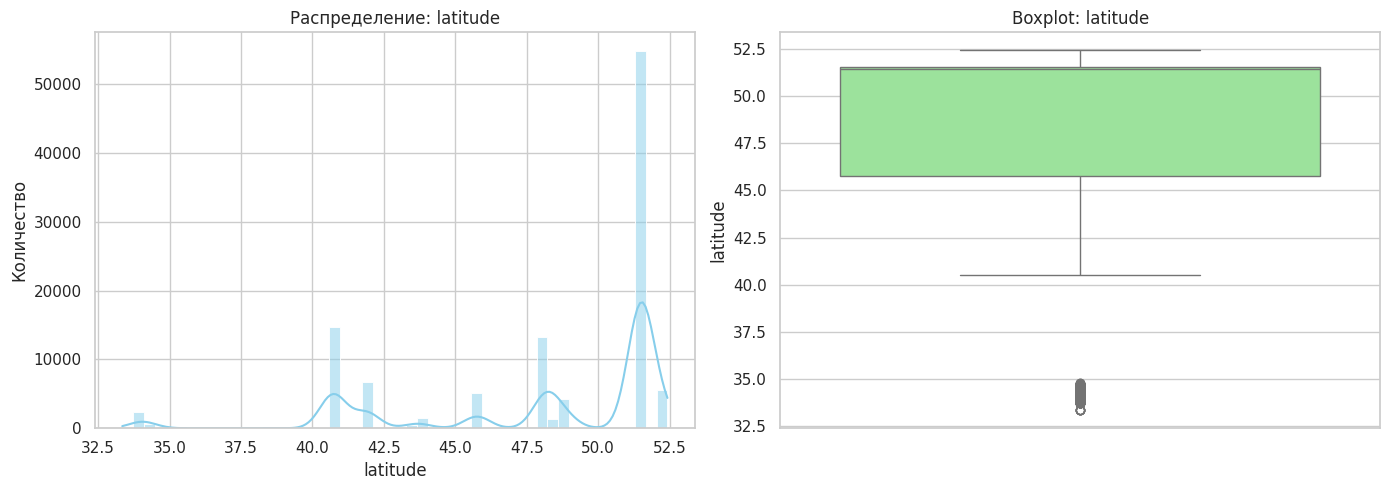


 Статистики для 'latitude':
  Среднее: 48.10
  Медиана: 51.45
  Мин: 33.34
  Макс: 52.43
  Стандартное отклонение: 4.71


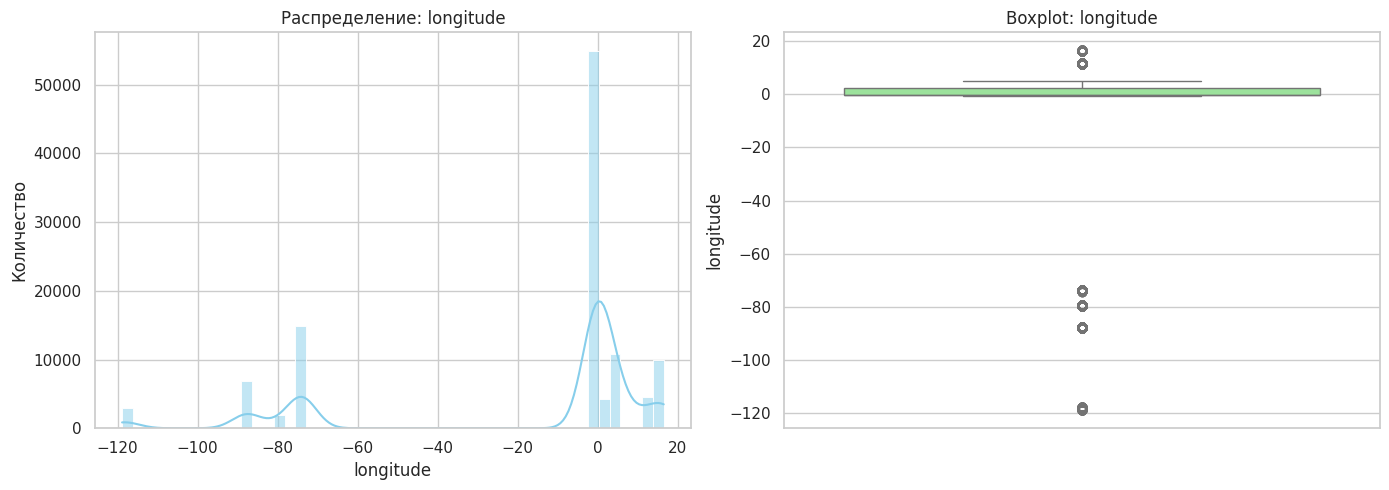


 Статистики для 'longitude':
  Среднее: -17.49
  Медиана: -0.13
  Мин: -118.90
  Макс: 16.53
  Стандартное отклонение: 37.70


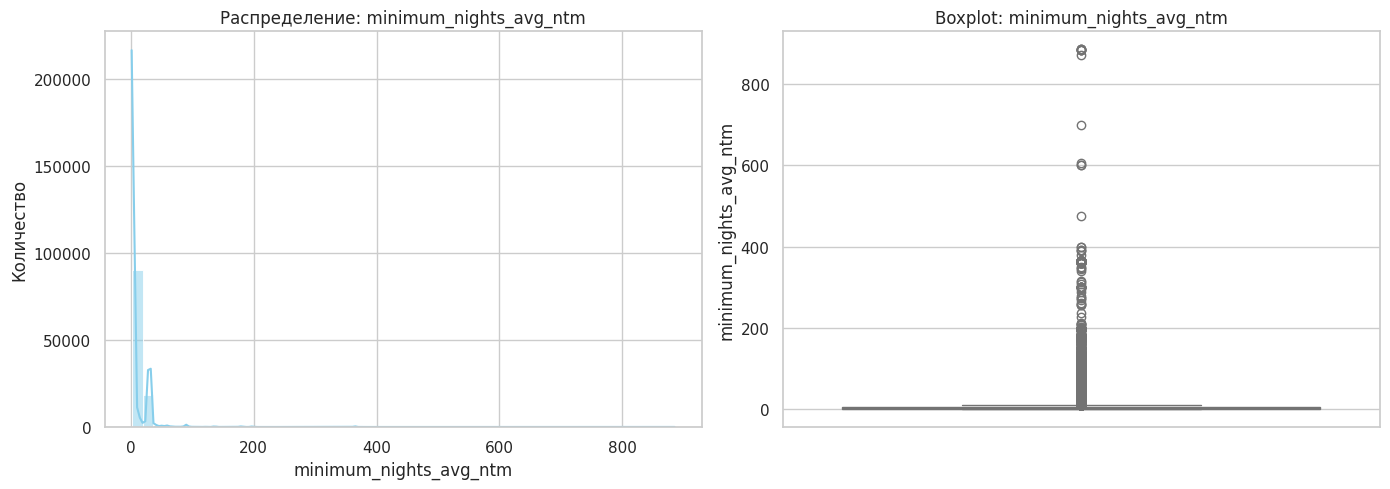


 Статистики для 'minimum_nights_avg_ntm':
  Среднее: 9.42
  Медиана: 2.80
  Мин: 1.00
  Макс: 885.70
  Стандартное отклонение: 22.08


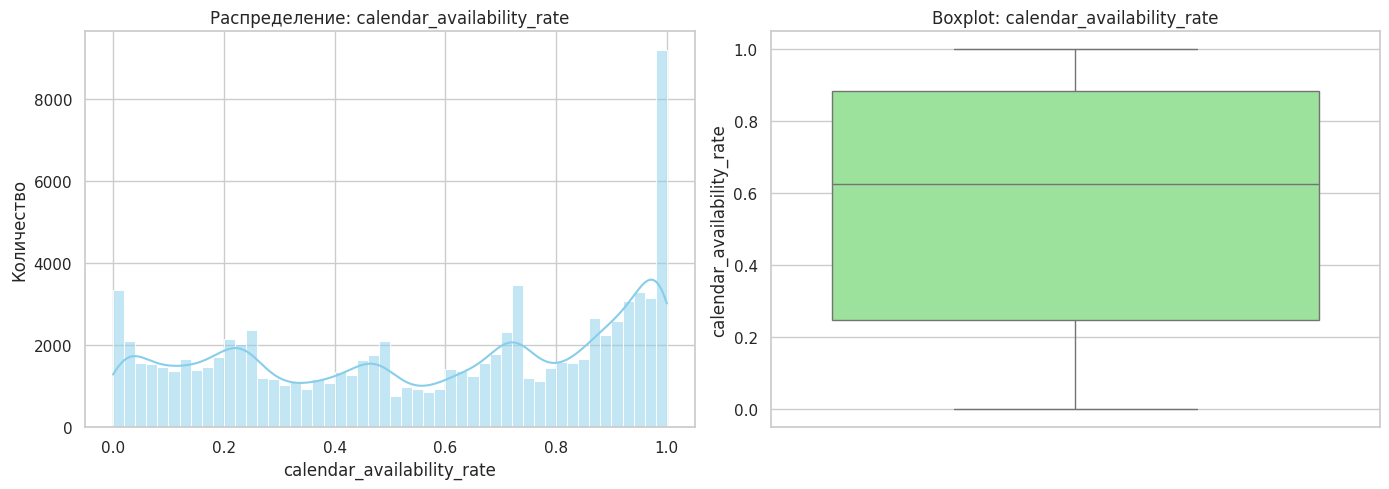


 Статистики для 'calendar_availability_rate':
  Среднее: 0.57
  Медиана: 0.62
  Мин: 0.00
  Макс: 1.00
  Стандартное отклонение: 0.33


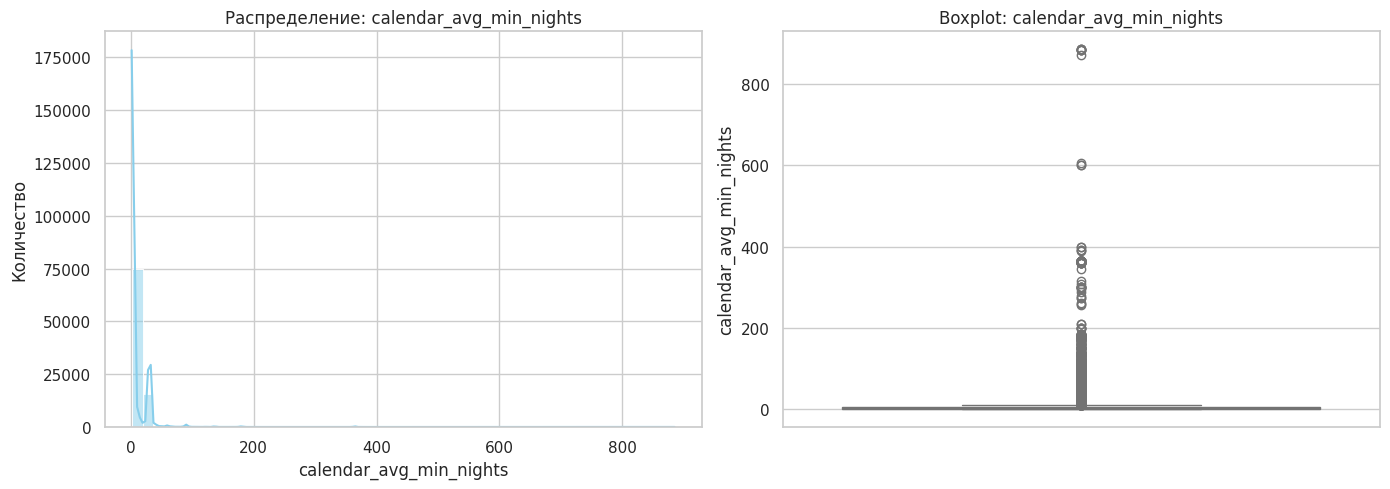


 Статистики для 'calendar_avg_min_nights':
  Среднее: 9.32
  Медиана: 2.92
  Мин: 1.00
  Макс: 885.73
  Стандартное отклонение: 21.17


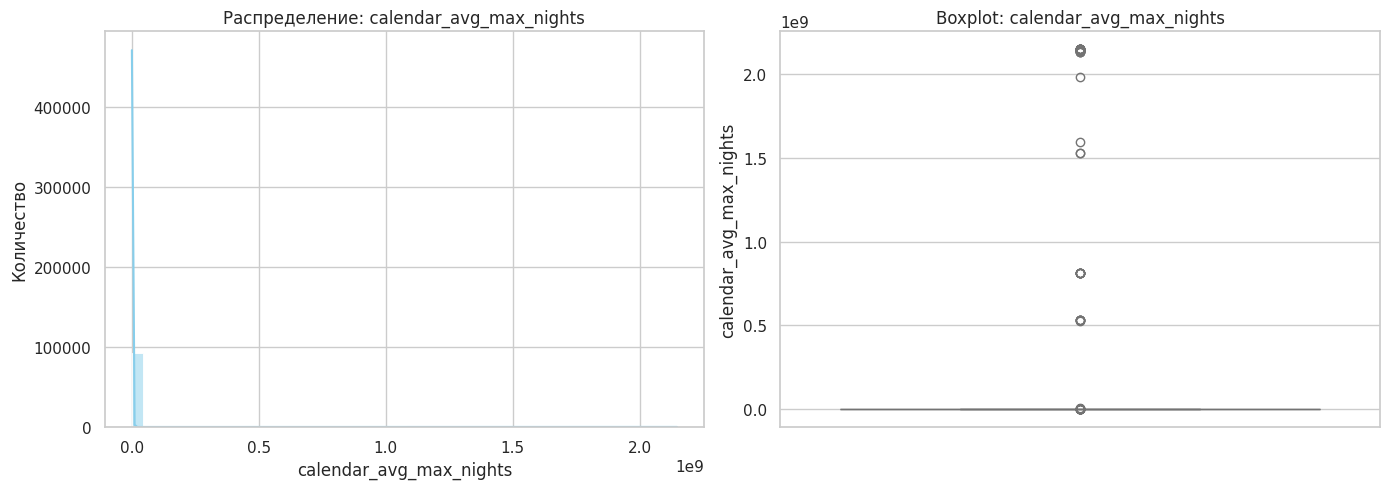


 Статистики для 'calendar_avg_max_nights':
  Среднее: 595142.71
  Медиана: 365.00
  Мин: 1.00
  Макс: 2147483647.00
  Стандартное отклонение: 33023059.77


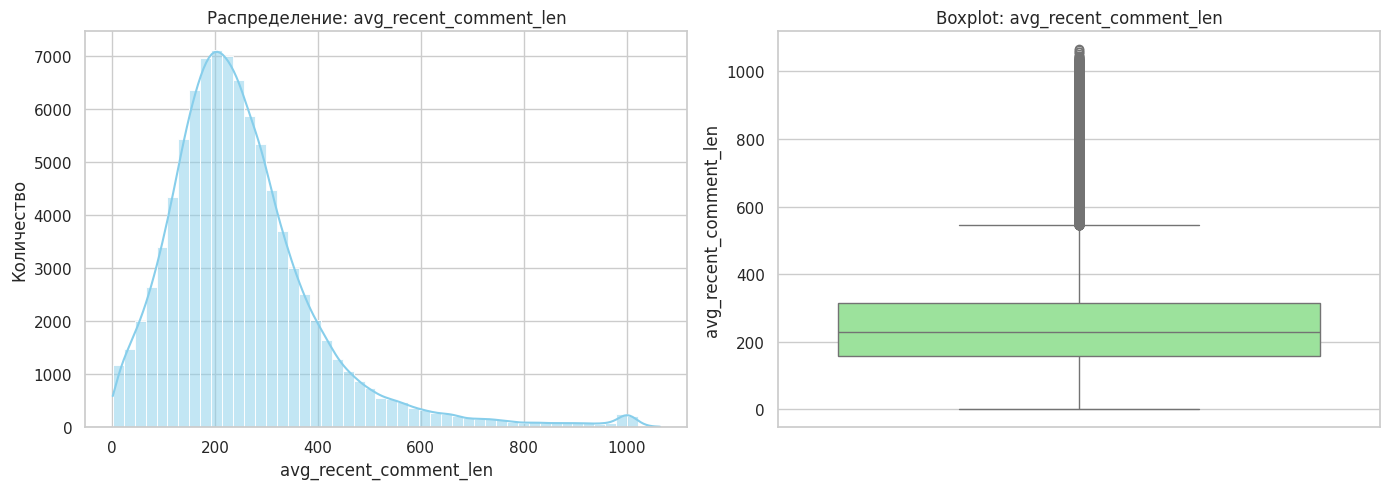


 Статистики для 'avg_recent_comment_len':
  Среднее: 252.67
  Медиана: 228.80
  Мин: 1.00
  Макс: 1065.00
  Стандартное отклонение: 148.89


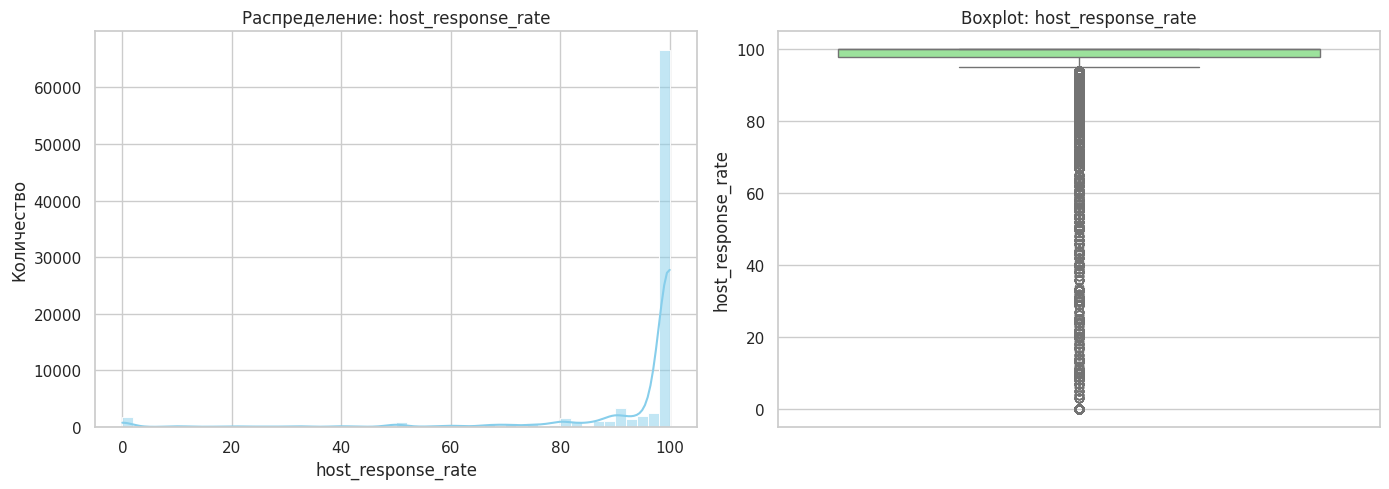


 Статистики для 'host_response_rate':
  Среднее: 93.30
  Медиана: 100.00
  Мин: 0.00
  Макс: 100.00
  Стандартное отклонение: 18.50


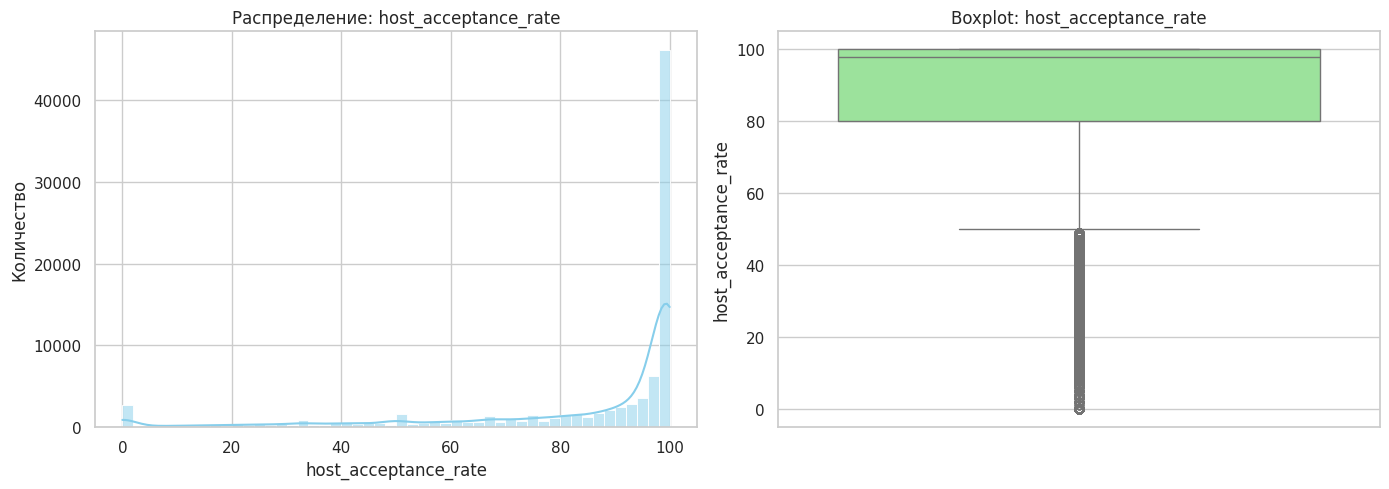


 Статистики для 'host_acceptance_rate':
  Среднее: 84.51
  Медиана: 98.00
  Мин: 0.00
  Макс: 100.00
  Стандартное отклонение: 25.21


In [57]:
for column in continuous_features:
    plot_continuous_feature_distribution(df_final_features, column, title=None)

`latitude`, `longitude` - не информативны сами по себе

`calendar_availability_rate` (доля дней, когда календарь открыт)

На визуализации заметны пики значений: у 0 (около 84 тысяч объявлений) и у 1 (около 31 тысячи). Объявления делятся на группы:

  - календарь закрыт весь год (0): хост не принимает гостей;
  - календарь открыт весь год (1);
  - всё остальное, где часть дней занята или закрыта.

`calendar_avg_min_nights` (среднее минимальное число ночей по календарю)

Почти все значения прижаты к левому краю (1–30 ночей), но есть отдельный пик около 365–400 ночей и длинный хвост до 1 125.

Есть группы:

  - обычная посуточная аренда (минимум 1–3 ночи)
  - объявления с минимумом «около года», то есть фактически долгосрочная аренда или объекты, закрытые от гостей.
  

`minimum_nights_avg_ntm` (среднее минимальное число ночей на ближайшие месяцы)

Графики практически совпадают с calendar_avg_min_nights: основная масса 1–30 ночей, пик около 365 и хвост до 1 125.

Это почти тот же признак, посчитанный другим способом, поэтому и картина та же: две группы (посуточная аренда и «минимум около года»).

Необходимо обрезать сверху на 400 - обрезка по 99-му перцентилю здесь опасна: она могла бы срезать 365.

Далее оставить только один из minimum_nights_avg_ntm, calendar_avg_min_nights и minimum_nights, чтобы не повторять один и тот же сигнал.

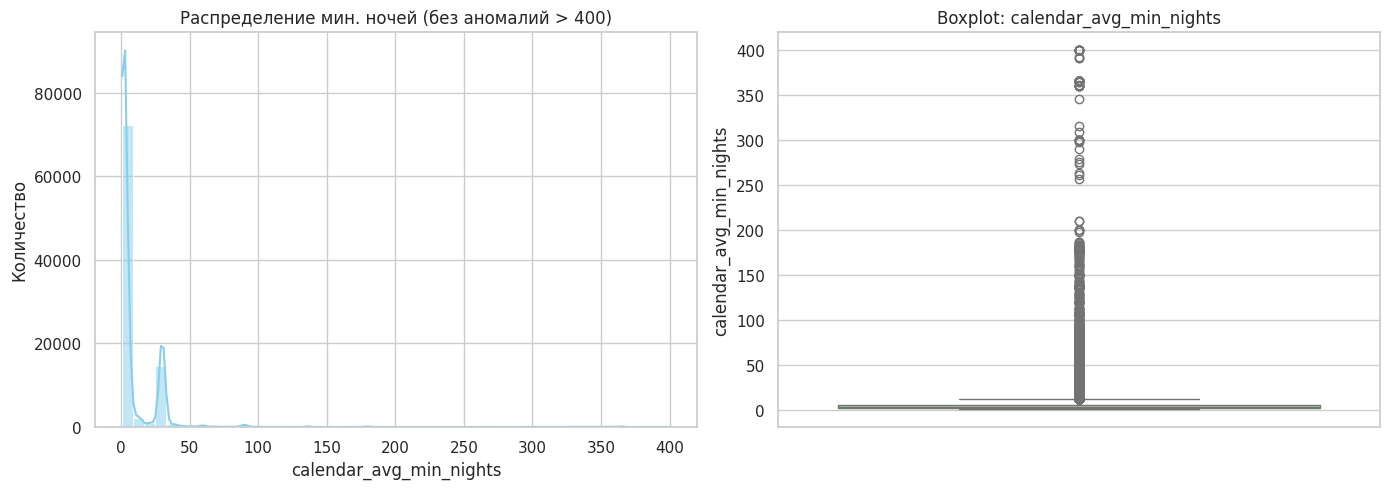


 Статистики для 'calendar_avg_min_nights':
  Среднее: 9.28
  Медиана: 2.92
  Мин: 1.00
  Макс: 400.00
  Стандартное отклонение: 19.72


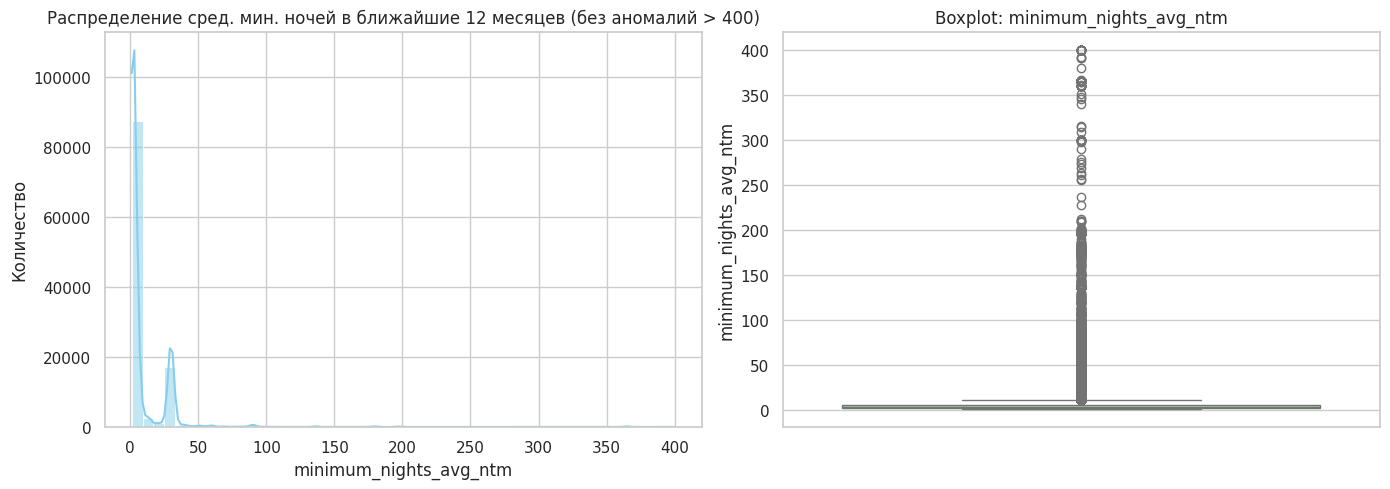


 Статистики для 'minimum_nights_avg_ntm':
  Среднее: 9.38
  Медиана: 2.80
  Мин: 1.00
  Макс: 400.00
  Стандартное отклонение: 20.85


In [58]:
# Обрезаем слишком большие значения: всё, что больше 400, становится равным 400
df_final_features['calendar_avg_min_nights'] = df_final_features['calendar_avg_min_nights'].clip(upper=400)
df_final_features['minimum_nights_avg_ntm'] = df_final_features['minimum_nights_avg_ntm'].clip(upper=400)

plot_continuous_feature_distribution(
    df_final_features,
    'calendar_avg_min_nights',
    title='Распределение мин. ночей (без аномалий > 400)'
)

plot_continuous_feature_distribution(
    df_final_features,
    'minimum_nights_avg_ntm',
    title='Распределение сред. мин. ночей в ближайшие 12 месяцев (без аномалий > 400)'
)

`calendar_avg_max_nights` - Наблюдается аномалия:

  * Среднее 362 878 при медиане 365
  * 2 147 483 647 - это ен настоящее значение а заглушка (предел целых чисел)
  * Реальные значения лежат в диапазоне до 1 125

  Также графиги с maximum_nights  дублируют друг друга, нужно в дальнейшем убрать один из признаков

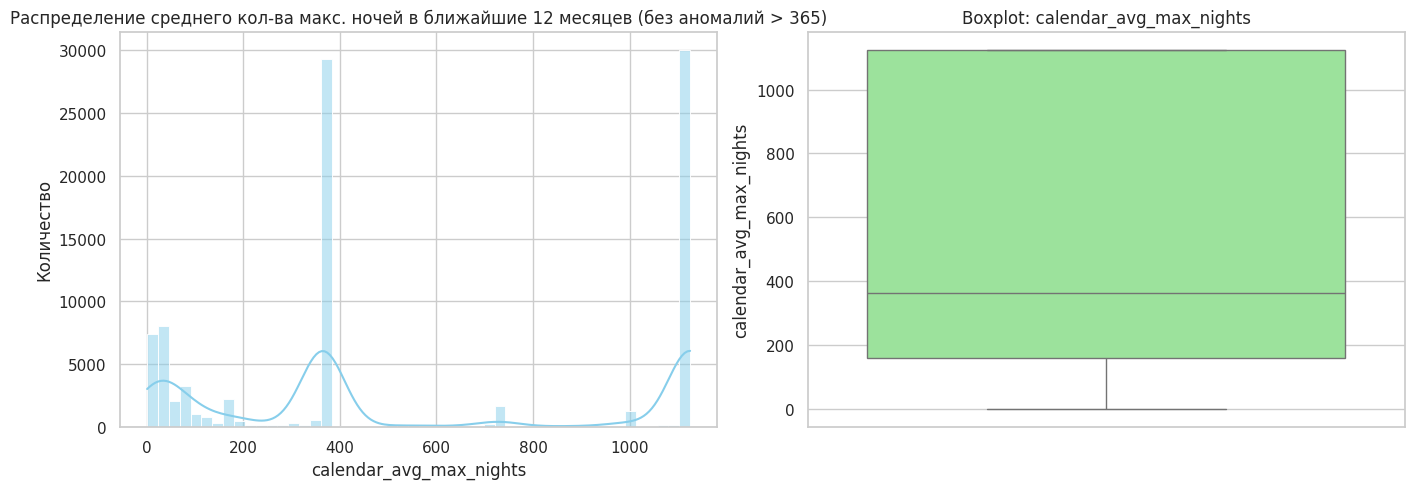


 Статистики для 'calendar_avg_max_nights':
  Среднее: 551.33
  Медиана: 365.00
  Мин: 1.00
  Макс: 1125.00
  Стандартное отклонение: 440.09


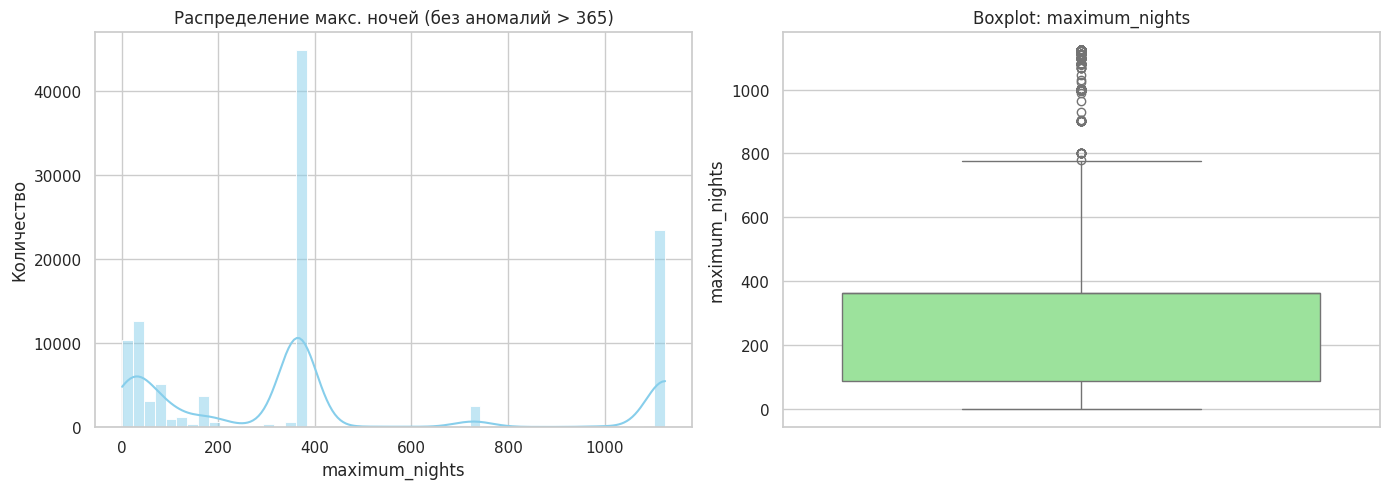


 Статистики для 'maximum_nights':
  Среднее: 432.21
  Медиана: 365.00
  Мин: 1.00
  Макс: 1125.00
  Стандартное отклонение: 394.08


In [59]:
# Значения больше 1125 - это "заглушка" (2 147 483 647), заменяем их на пропуск, т.к. реальные значения не известны
df_final_features.loc[df_final_features['calendar_avg_max_nights'] > 1125, 'calendar_avg_max_nights'] = np.nan
df_final_features.loc[df_final_features['maximum_nights'] > 1125, 'maximum_nights'] = np.nan

plot_continuous_feature_distribution(
    df_final_features,
    'calendar_avg_max_nights',
    title='Распределение среднего кол-ва макс. ночей в ближайшие 12 месяцев (без аномалий > 365)'
)

plot_continuous_feature_distribution(
    df_final_features,
    'maximum_nights',
    title='Распределение макс. ночей (без аномалий > 365)'
)

`avg_recent_comment_len` (средняя длина свежих отзывов, символов)

Единственный график с понятной «колоколообразной» формой со сдвигом вправо: большинство отзывов 100–400 символов, пик около 200. Медиана 227, среднее 257, максимум 1 065. Есть небольшой всплеск около 1 000.

Люди чаще всего пишут короткие отзывы, редко длинные.

Значение есть только у объектов, у которых были свежие отзывы (около 37%). У остальных около 63% пропуск. Это значит, что признак частично говорит «у объекта были отзывы», а это близко к самому таргету.

Выбросы не трогаем, пропуски не заполняяем.

`host_response_rate` и `host_acceptance_rate` имеют похожий паттерн распределения: хвост слева говорит о том, что имеются имеются хосты с маленьким количеством доли отвеченных запросов, принятых бронирвоаний, что может быть При этом основное количество объявлений принадлежит хостам с высокой долей


In [60]:
#удаляем minimum_nights_avg_ntm
df_final_features = df_final_features.drop(columns=['minimum_nights_avg_ntm'])

In [61]:
df_final_features.columns

Index(['city', 'room_type', 'property_type', 'first_review', 'last_review',
       'host_response_time', 'host_is_superhost', 'host_listings_count',
       'host_identity_verified', 'minimum_nights', 'maximum_nights',
       'instant_bookable', 'availability_eoy', 'accommodates', 'bedrooms',
       'beds', 'bathrooms', 'latitude', 'longitude', 'neighbourhood_cleansed',
       'host_since', 'host_response_rate', 'host_acceptance_rate',
       'host_total_listings_count', 'host_has_profile_pic',
       'calculated_host_listings_count',
       'calculated_host_listings_count_entire_homes',
       'calculated_host_listings_count_private_rooms', 'bathrooms_text',
       'amenities', 'name', 'calendar_availability_rate',
       'calendar_avg_min_nights', 'calendar_avg_max_nights',
       'avg_recent_comment_len', 'concat_recent_comments', 'is_high_demand'],
      dtype='object')

###### Дискретные числовые признаки

In [62]:
discrete_features

['host_listings_count',
 'host_total_listings_count',
 'calculated_host_listings_count',
 'calculated_host_listings_count_entire_homes',
 'calculated_host_listings_count_private_rooms',
 'minimum_nights',
 'maximum_nights',
 'availability_eoy',
 'accommodates',
 'bedrooms',
 'beds',
 'bathrooms']

In [63]:
# Анализ дискретных признаков
analysis_df = pd.DataFrame({
    'Тип данных (Dtype)': df_final_features[discrete_features].dtypes,
    'Кол-во уникальных значений (nunique)': df_final_features[discrete_features].nunique(),
    'Пример значений': [df_final_features[col].unique()[:5] for col in discrete_features] # первые 5 уникальных значений
})

display(analysis_df)

,Тип данных (Dtype),Кол-во уникальных значений (nunique),Пример значений
host_listings_count,float64,280,"[1.0, 2.0, 4.0, 3.0, 11.0]"
host_total_listings_count,float64,349,"[1.0, 2.0, 3.0, 6.0, 4.0]"
calculated_host_listings_count,float64,164,"[1.0, 2.0, 3.0, 8.0, 4.0]"
calculated_host_listings_count_entire_homes,float64,152,"[0.0, 1.0, 2.0, 9.0, 4.0]"
calculated_host_listings_count_private_rooms,float64,81,"[1.0, 2.0, 0.0, 3.0, 7.0]"
minimum_nights,float64,122,"[3.0, 2.0, 7.0, 4.0, 5.0]"
maximum_nights,float64,344,"[356.0, 730.0, 1125.0, 14.0, 18.0]"
availability_eoy,float64,331,"[17.0, 15.0, 13.0, 59.0, 101.0]"
accommodates,float64,16,"[2.0, 3.0, 4.0, 5.0, 8.0]"
bedrooms,float64,20,"[1.0, 2.0, 3.0, 5.0, 10.0]"


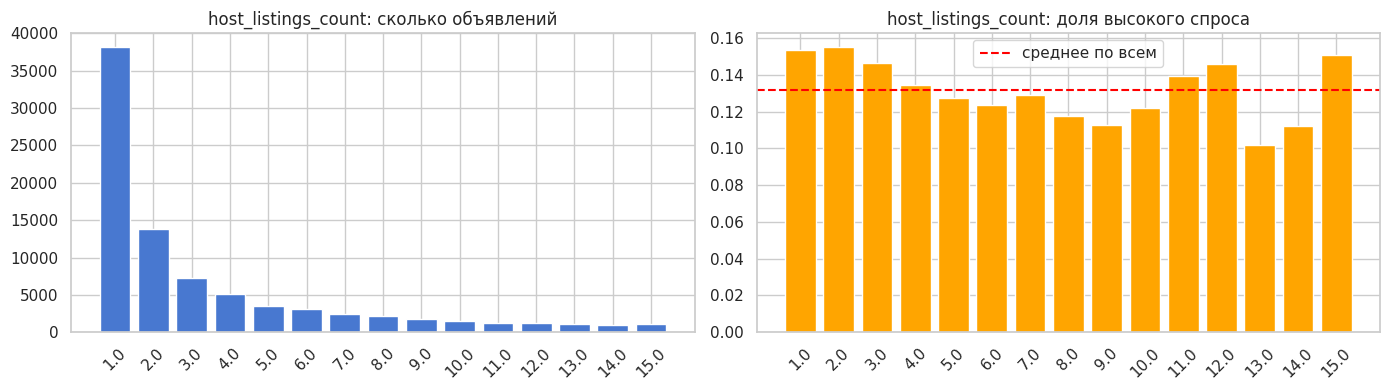

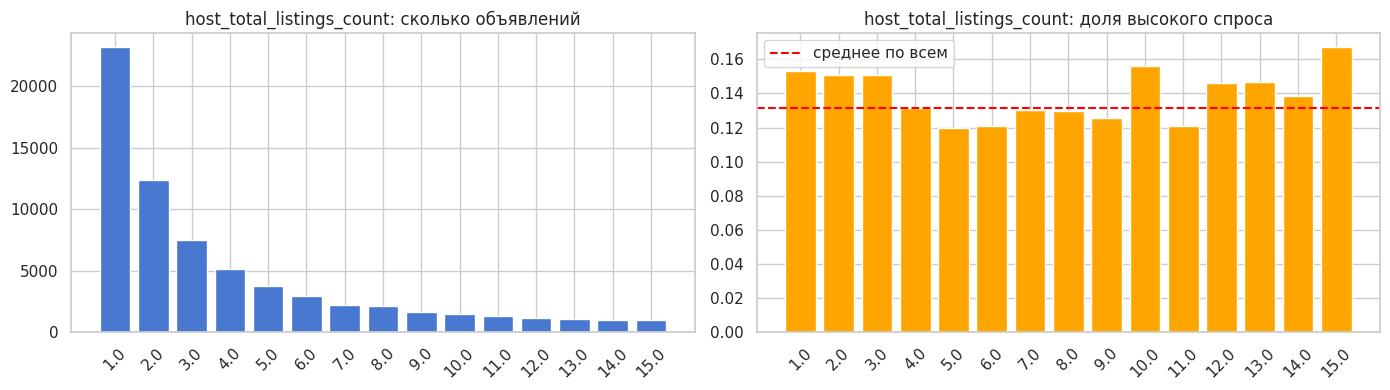

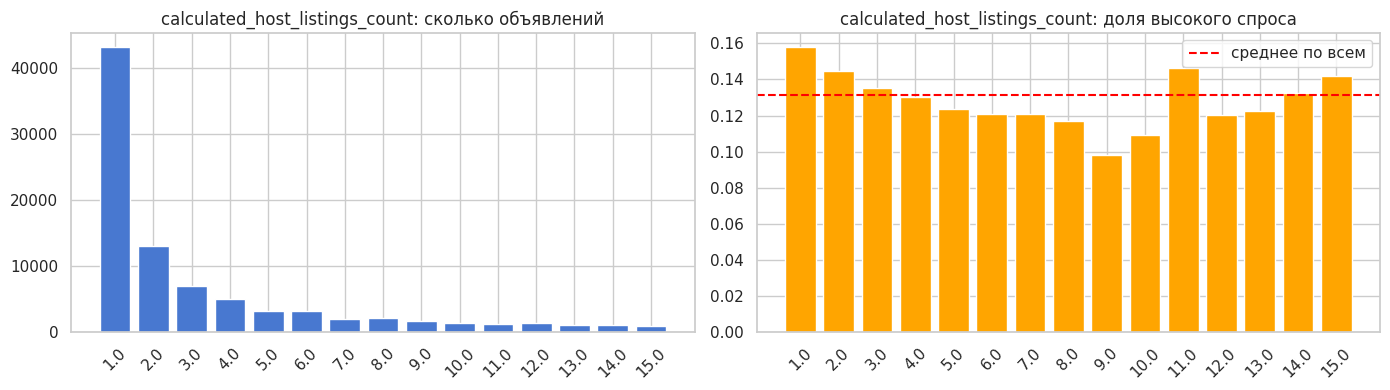

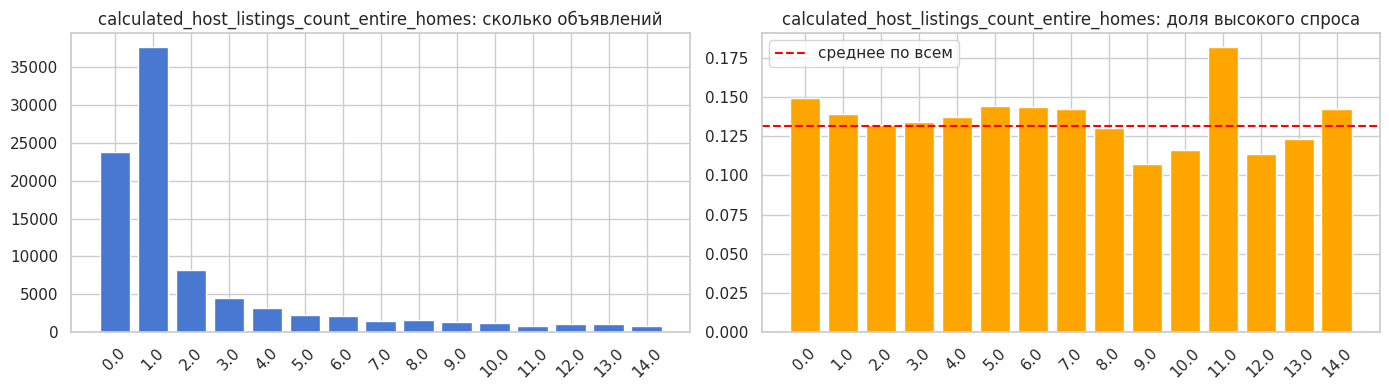

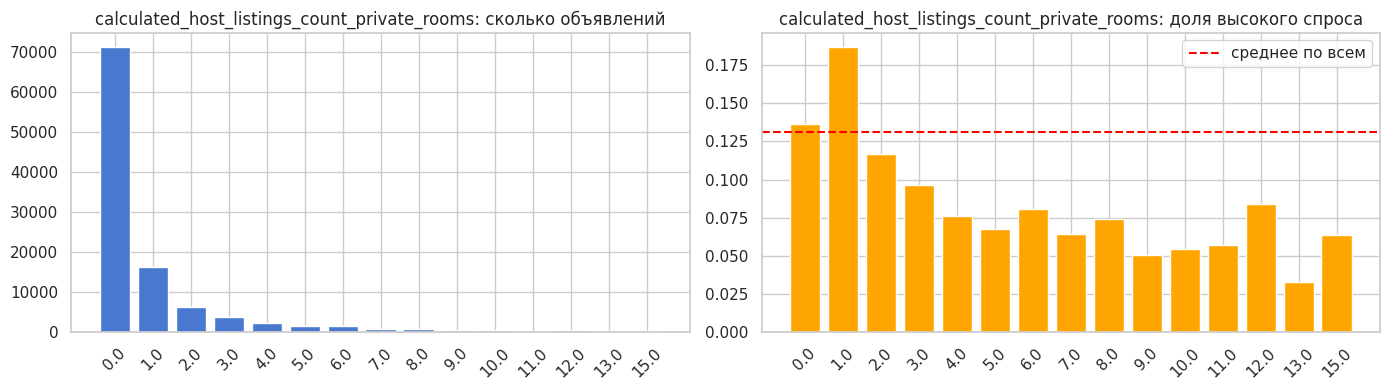

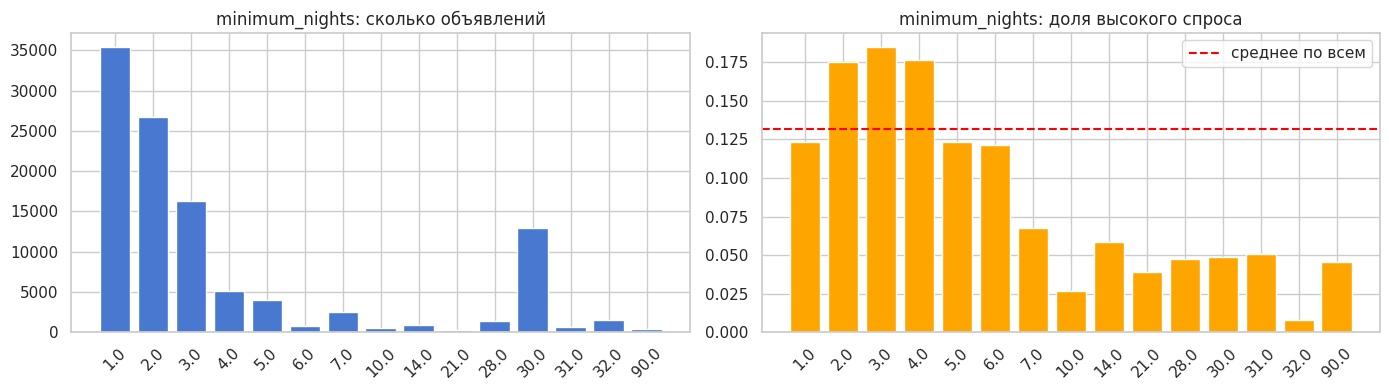

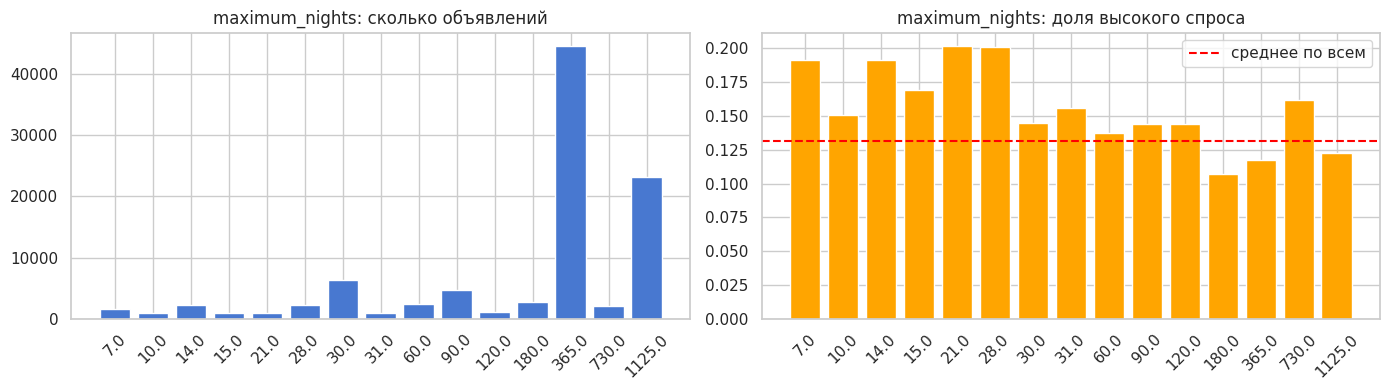

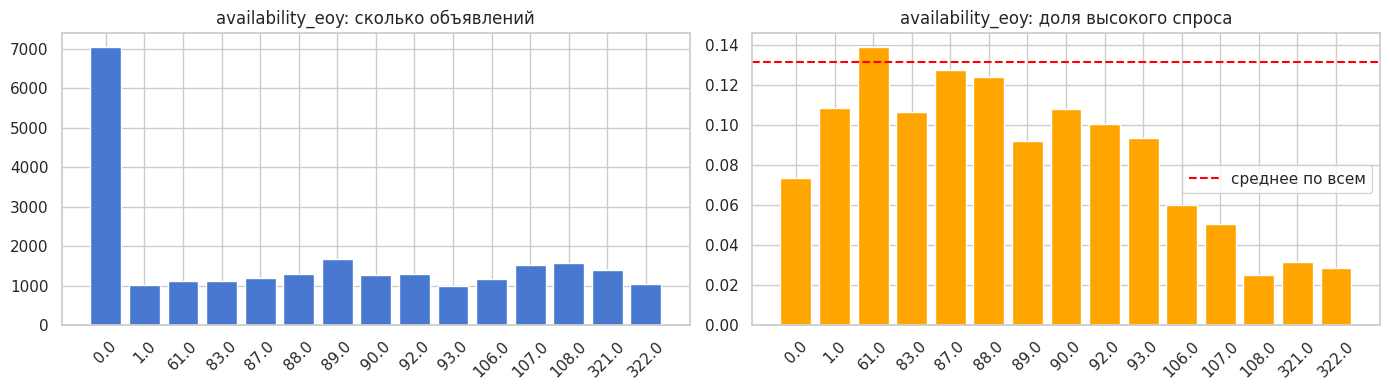

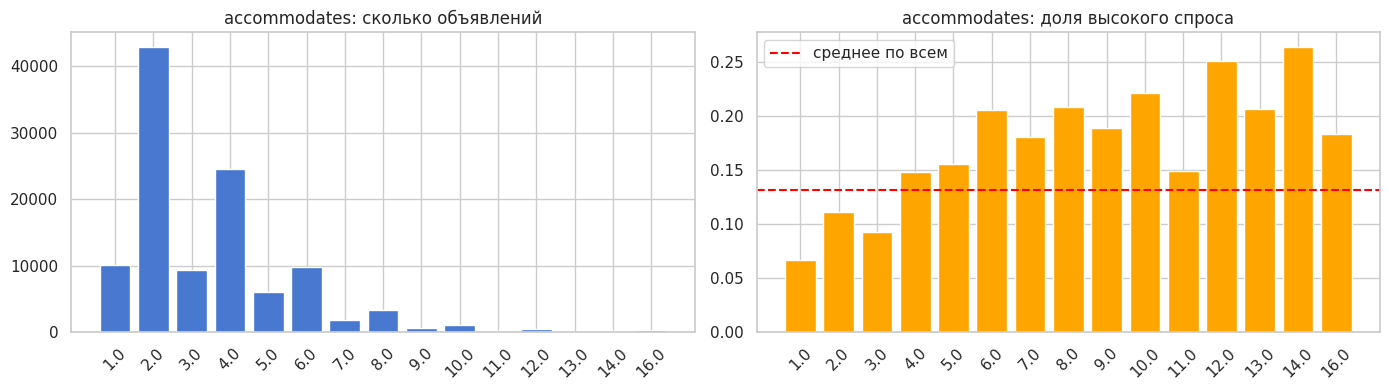

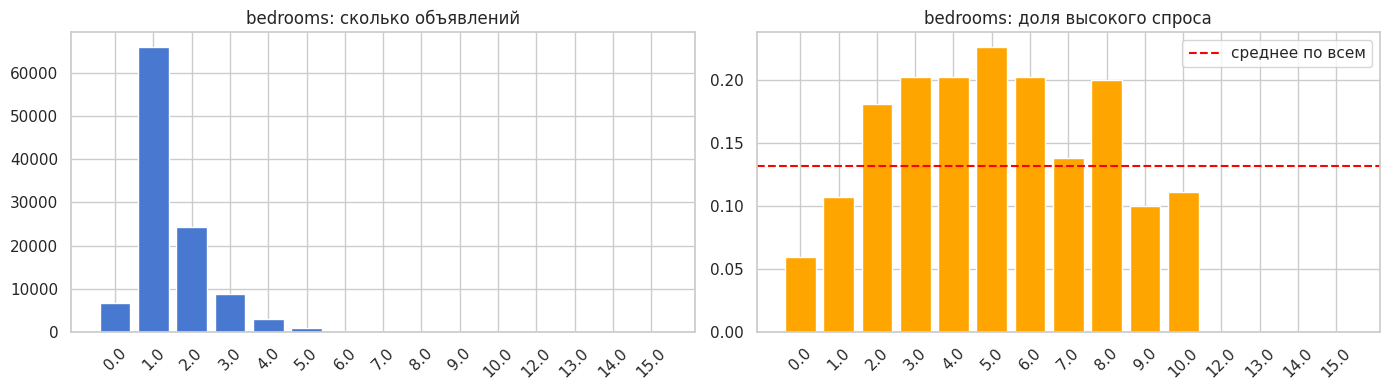

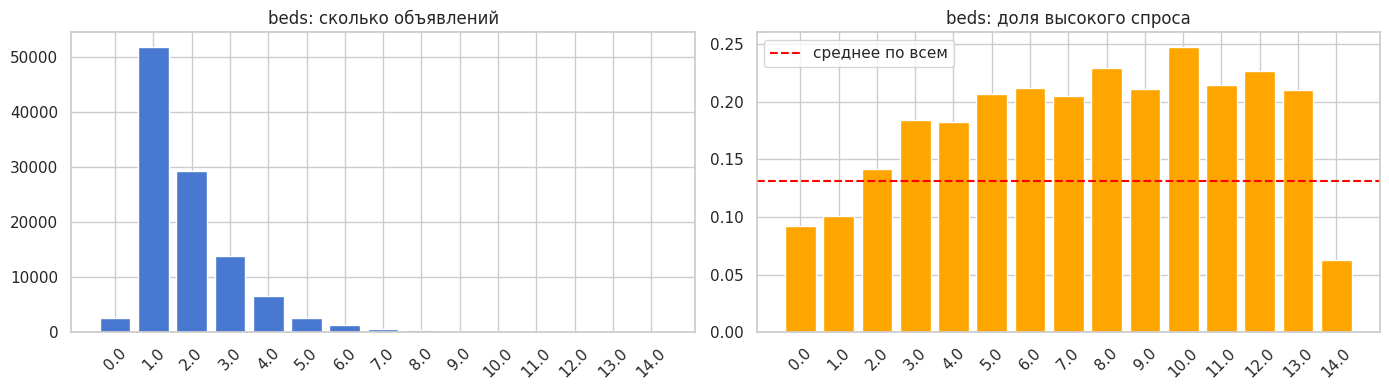

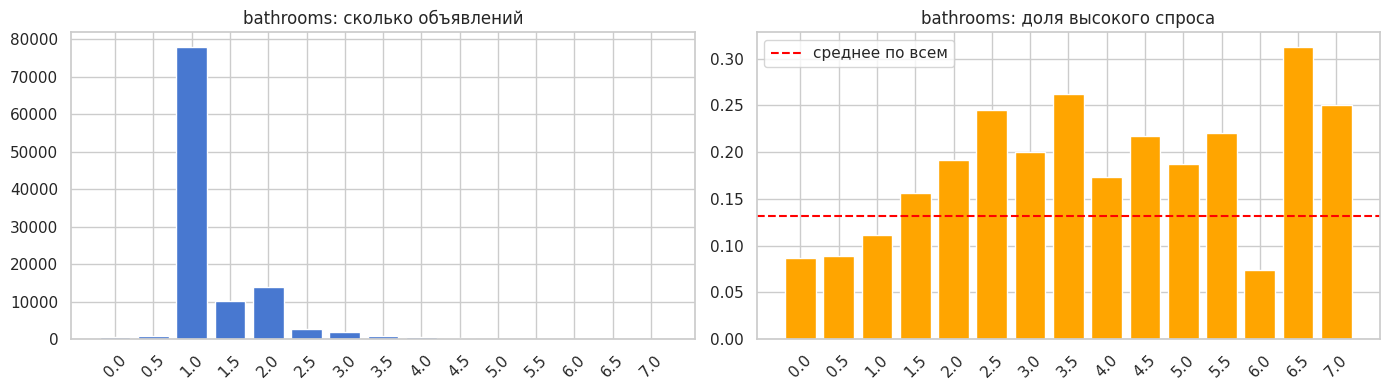

In [64]:
# Средняя доля высокого спроса по всей выборке (для красной линии)
mean_rate = df_final_features['is_high_demand'].mean()

for col in discrete_features:
    # Берём 15 самых частых значений признака
    top_values = df_final_features[col].value_counts().head(15).index
    data = df_final_features[df_final_features[col].isin(top_values)]

    # Считаем: сколько объявлений и какая доля высокого спроса для каждого значения
    counts = data[col].value_counts().sort_index()
    rate = data.groupby(col)['is_high_demand'].mean()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Левый график: сколько объявлений
    axes[0].bar(counts.index.astype(str), counts.values)
    axes[0].set_title(col + ': сколько объявлений')
    axes[0].tick_params(axis='x', rotation=45)

    # Правый график: доля высокого спроса
    axes[1].bar(rate.index.astype(str), rate.values, color='orange')
    axes[1].axhline(mean_rate, color='red', linestyle='--', label='среднее по всем')
    axes[1].set_title(col + ': доля высокого спроса')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

`host_listings_count` - У большинства хостов 1 объявление (около 132 тыс.), их доля высокого спроса около 6%, это ниже среднего. У хостов с 2–14 объявлениями доля 8–10%. Отдельный столбец 5230 даёт долю почти 0% (возможно ошибка)

In [65]:
# Проверяем откуда берётся 5230
df_final_features[df_final_features['host_listings_count'] == 5230]['city'].value_counts()

,count
city,
nyc,8


In [66]:
all_listings[all_listings['host_listings_count'] == 5230][['host_id']].value_counts()

,count
host_id,
107434423.0,1210


* Значение host_listings_count = 5230 принадлежит одному крупному оператору в 1 городе (около 1210 объявлений, почти нет высокого спроса); оставлено как есть

`host_total_listings_count`

Доля плавно растёт: около 6% при 1 объявлении и около 12% при 14–15.

Чем больше у хоста объявлений, тем выше шанс высокого спроса. Связь понятная и почти монотонная.

Это чистый из четырёх «хостовых» признаков, оставим его.

`calculated_host_listings_count`

Больше всего хостов с 1 объявлением

host_total_listings_count, его можно убрать (после проверки корреляцию).

`calculated_host_listings_count_entire_homes`

Хосты, у которых 1 квартира, дают около 6% признака высокого спроса. Значения 3–8 около 9–11%. На больших значениях столбцы прыгают (до 13%), но там мало объявлений.

Больше «квартир целиком» у хоста слегка повышает шанс высокого спроса.


Оставим как есть.

`calculated_host_listings_count_private_rooms`

Тенденция обратная: 1–3 комнаты дают 7,5–8,5%, а от 4 и больше доля падает до 4,5–6%. Основная масса (184 тыс.) это 0.

Хосты с множеством отдельных комнат чаще ниже по спросу. Но справа объявлений очень мало, поэтому не стоит делать из этого сильных выводов.

Оставим, это единственный признак с отрицательной связью.

`minimum_nights` (информативный)


Доля быстро падает с ростом минимума: 2–4 ночи дают около 10,5–12%, 5 ночей около 7,5%, 10–14 ночей около 3–4%, от 28 и выше 1–2%, а 365 почти 0%.

Есть два горба по количеству: 1–3 ночи и 28–30 ночей.
Посуточные объявления попадают в высокий спрос в 5–10 раз чаще долгосрочных.

Оставим, нелинейная связь, для ансамблей деревьем подходит Связь не линейная (резкий спад после 5 и после 30)

`maximum_nights`

Почти 190 тыс. объявлений имеют значение 365, их доля около 6%.

Остальные значения встречаются редко и дают 2–13%, причём сильно скачут.
Что значит. Один столбец содержит около 60% данных, остальное шум из маленьких групп. Явной закономерности нет.


`availability_eoy` (сколько дней свободно до конца года)

Объявление без свободных дней до конца года почти никогда не попадает в высокий спрос. Скорее всего, календарь у них закрыт.

Признак сильный, оставим.

`accommodates` (Максимальное количество гостей)

Доля почти монотонно растёт: 1 гость около 3,7%, 2 гостя около 5,7%, 4 гостя около 8%, 6 гостей около 12%, 13 гостей около 18%.

Чем вместительнее жильё, тем чаще высокий спрос.

Один из самых полезных признаков, оставим.

`bedrooms`

0 спален около 5%, 1 спальня около 6,6% (самая большая группа, 147 тыс.), 2 спальни около 10%, 3–6 спален 11–12%. Справа значения скачут (8 спален около 14%, 9–10 около 3%, а 11 и больше нулевые), но там почти нет объявлений.

Рост до 3 спален понятен и надёжен, после этого график шумный из-за редких объектов.
Оставим.`

`beds`

0–1 кровать около 8,5–9%, 2 кровати около 12,5%, 3–4 кровати около 16%, а дальше 15–21% с шумом.

Больше кроватей, чаще высокий спрос, и эта связь даже сильнее, чем у bedrooms.

Кровати, спальни и accommodates сильно связаны между собой, но для деревьев это не проблема.

`bathrooms`

Что видно. 1 ванная (116 тыс. объявлений) около 10%, 1,5–2 ванные около 15–16%, 2,5 и 3,5 ванных около 21–22%. Начиная с 4 и выше доля падает до 6–12%, но там мало данных.

доля при 1 ванной уже выше средней по выборке (10% против 7%), хотя 1 ванная это самое обычное жильё. Значит, у объявлений без указанных ванных (пропуски) доля заметно ниже.

Оставим и проверим влияние пропусков:

In [67]:
df_final_features.groupby(df_final_features['bathrooms'].isna())['is_high_demand'].mean()

,is_high_demand
bathrooms,
False,0.131978
True,0.094797


Если количество ванных указано, высокий спрос у 13,2% объявлений, если не указано (пропуск) - у 9,5%.

Разница небольшая, поэтому пропуск в bathrooms слабо связан с классом 0.

Заменим пропуски на значения из столбца bathrooms_text.

In [68]:
df_final_features['bathrooms_text'].isna().sum()

np.int64(119)

In [69]:
df_final_features['bathrooms'].isna().sum()

np.int64(1403)

In [70]:
df_final_features[['bathrooms_text','bathrooms']].head(100)

,bathrooms_text,bathrooms
0,1.5 baths,1.5
1,1 shared bath,1.0
2,1 shared bath,1.0
3,1 bath,1.0
4,1.5 baths,1.5
...,...,...
95,1.5 baths,1.5
96,1 bath,1.0
97,1.5 baths,1.5
98,1 bath,1.0


In [71]:
# Достаём число из текста: "1.5 baths" -> 1.5, "1 shared bath" -> 1.0
bath_from_text = df_final_features['bathrooms_text'].str.extract(r'(\d+\.?\d*)')[0].astype(float)

# Тексты без цифры, например "Half-bath", считаем как 0.5
is_half = df_final_features['bathrooms_text'].str.contains('half', case=False, na=False)
bath_from_text[is_half] = 0.5

# Подставляем число из текста только туда, где в bathrooms был пропуск
df_final_features['bathrooms'] = df_final_features['bathrooms'].fillna(bath_from_text)

In [72]:
df_final_features['bathrooms'].isna().sum()

np.int64(55)

количество пропусков в bathrooms значительно сократилось

bathrooms_text можно убрать из обучения модели

### 5.2 Категориальные признаки

In [73]:
category_features = df_final_features.select_dtypes(include='object').columns.to_list()
category_features

['city',
 'room_type',
 'property_type',
 'first_review',
 'last_review',
 'host_response_time',
 'host_is_superhost',
 'host_identity_verified',
 'instant_bookable',
 'neighbourhood_cleansed',
 'host_since',
 'host_has_profile_pic',
 'bathrooms_text',
 'amenities',
 'name',
 'concat_recent_comments']

In [74]:
df_final_features[category_features].head()

,city,room_type,property_type,first_review,last_review,host_response_time,host_is_superhost,host_identity_verified,instant_bookable,neighbourhood_cleansed,host_since,host_has_profile_pic,bathrooms_text,amenities,name,concat_recent_comments
0,amsterdam,Private room,Private room in houseboat,2012-01-09,2025-09-07,within an hour,True,True,False,Centrum-West,2010-03-23,True,1.5 baths,"[""Canal view"", ""Coffee"", ""Private backyard \u2...","Романтический, стильный плавучий дом типа «пос...",We loved staying on the boat. The space was co...
1,amsterdam,Private room,Private room in rental unit,2010-08-22,2025-09-07,within an hour,True,True,False,Centrum-West,2010-05-13,True,1 shared bath,"[""Heating"", ""Lock on bedroom door"", ""Hair drye...",Комфортабельный двухместный номер,Edwin was very nice and the room was amazing. ...
2,amsterdam,Private room,Private room in condo,2011-03-16,2025-09-08,within an hour,True,True,False,Centrum-Oost,2010-05-13,True,1 shared bath,"[""Heating"", ""Lock on bedroom door"", ""Hair drye...",Комфортабельный одноместный/двухместный номер,Edwin war super freundlich und die Unterkunft ...
3,amsterdam,Entire home/apt,Entire guest suite,2010-10-29,2025-08-26,within a few hours,True,True,False,Centrum-West,2010-09-06,True,1 bath,"[""Coffee"", ""Bikes"", ""Portable fans"", ""Toaster""...",Роскошный гостевой люкс Multatuli в отличном м...,We loved our stay! The location was perfect an...
4,amsterdam,Entire home/apt,Entire condo,2010-10-13,2025-09-01,within an hour,False,True,False,Centrum-Oost,2010-09-10,True,1.5 baths,"[""Pets allowed"", ""BBQ grill"", ""Free dryer \u20...","Central de Lux 2 спальни (4 человека), кв. 125...","The location was perfect, with everything we n..."


* Убираем из категориальных признаков даты - они понадобятся для Feature Engineering:

      first_review
      last_review
      host_since

* Убираем текстовые признаки:

      name, amenities, bathrooms_text(обработан ранее в дискретных признаках), concat_recent_comments

* Остальные категориальные признаки приводим к типу category, для используемых ансамблевых моделей этого преобразования будет достаточно:

  * Категориальные (мало значений)
      city, room_type, host_response_time, host_is_superhost, host_identity_verified, instant_bookable, host_has_profile_pic

  * Категориальные (с большим числом значений)
    property_type, neighbourhood_cleansed

In [75]:
# категориальные признаки
categorical_features = [
    'city',
    'room_type',
    'host_response_time',
    'host_is_superhost',
    'host_identity_verified',
    'instant_bookable',
    'host_has_profile_pic'
]

high_card_features = [
    'property_type',
    'neighbourhood_cleansed'
]

In [76]:
# преобразуем категориальные признаки к типу category
# bool-признаки приводим к типу str до category, иначе после добавления 'Missing' типы смешаются
bool_like = ['host_is_superhost', 'host_identity_verified', 'instant_bookable','host_has_profile_pic']
for c in bool_like:
    df_final_features[c] = df_final_features[c].astype(str).replace({'nan':'Missing','None':'Missing'})

In [77]:
# Остальных object типа признаках также заполняем nan - Missing
cat_cols=['city','room_type','host_response_time','property_type','neighbourhood_cleansed']
for col in cat_cols:
   df_final_features[col] = df_final_features[col].fillna('Missing')

In [78]:
# приводим все категориальные признаки к типу category
full_cat_cols = bool_like + cat_cols
for col in full_cat_cols:
  df_final_features[col] = df_final_features[col].astype('category')
#df_final_features[full_cat_cols].info()

In [79]:
for col in categorical_features + high_card_features:
    print(col, '| уникальных:', df_final_features[col].nunique(), '| пропусков:', df_final_features[col].isna().sum())

city | уникальных: 10 | пропусков: 0
room_type | уникальных: 4 | пропусков: 0
host_response_time | уникальных: 5 | пропусков: 0
host_is_superhost | уникальных: 3 | пропусков: 0
host_identity_verified | уникальных: 3 | пропусков: 0
instant_bookable | уникальных: 3 | пропусков: 0
host_has_profile_pic | уникальных: 3 | пропусков: 0
property_type | уникальных: 100 | пропусков: 0
neighbourhood_cleansed | уникальных: 764 | пропусков: 0


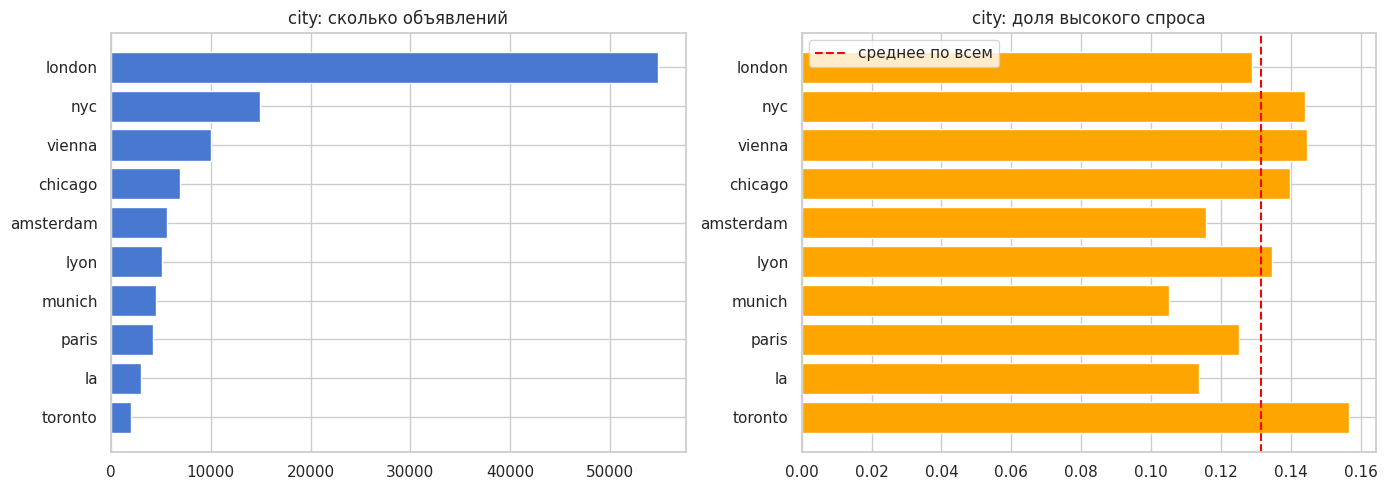

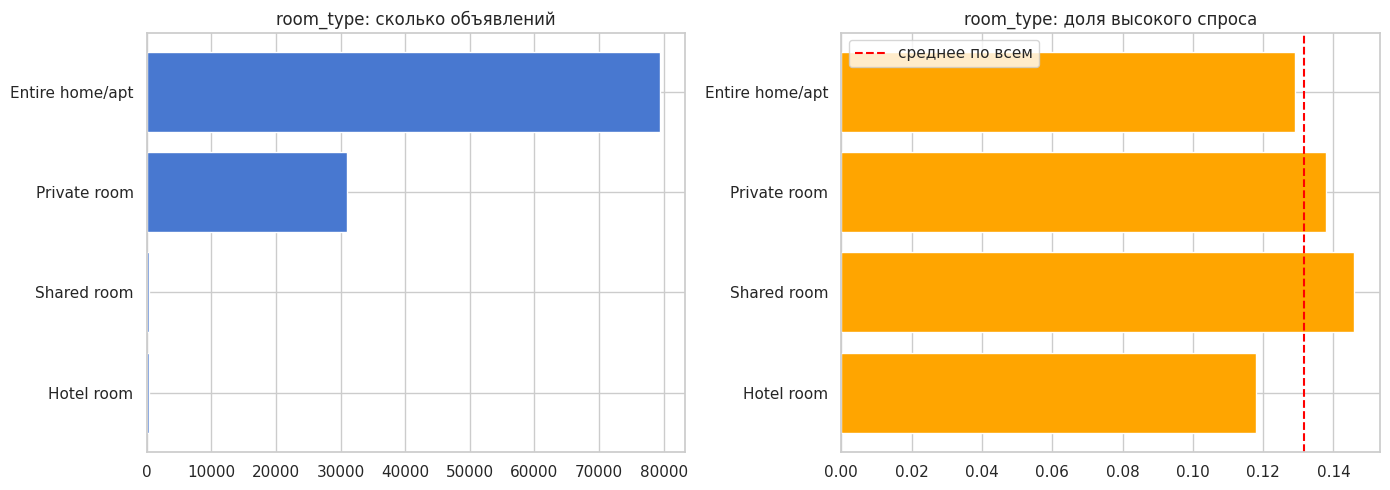

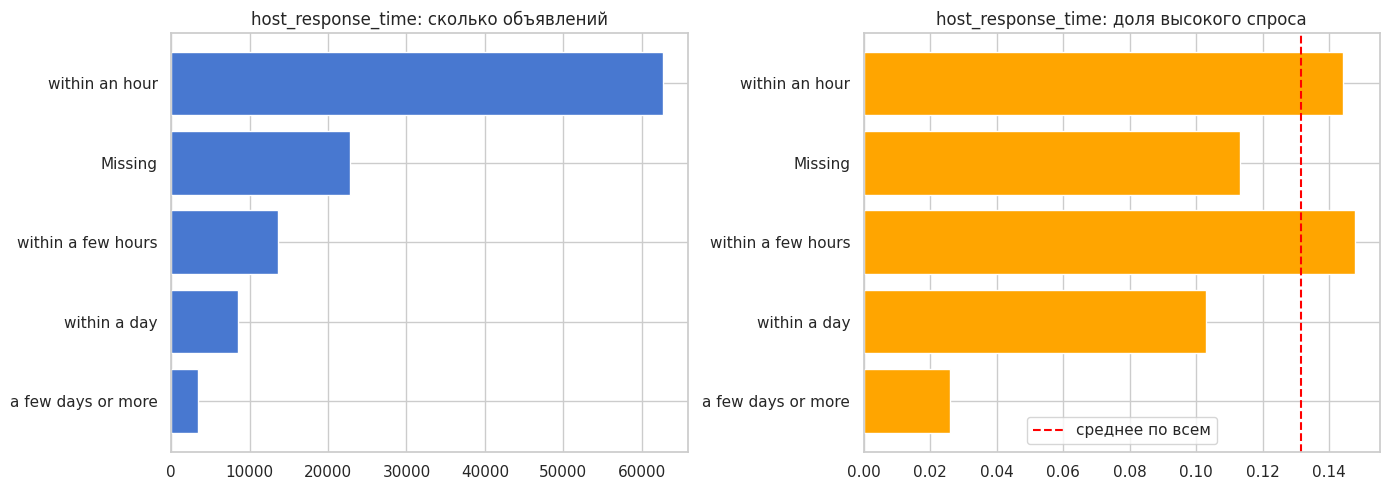

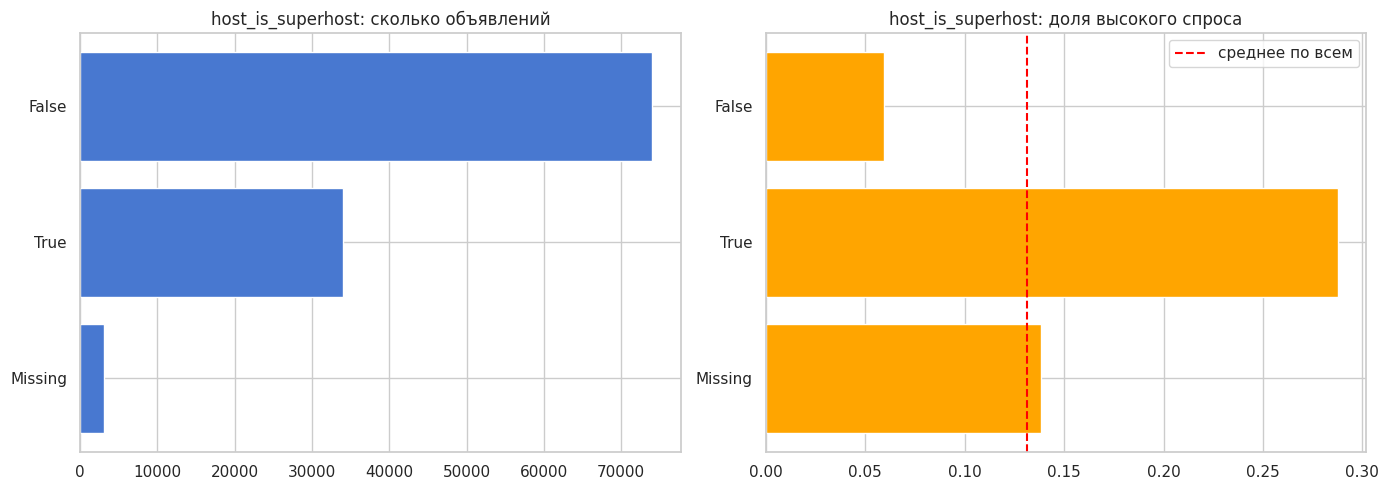

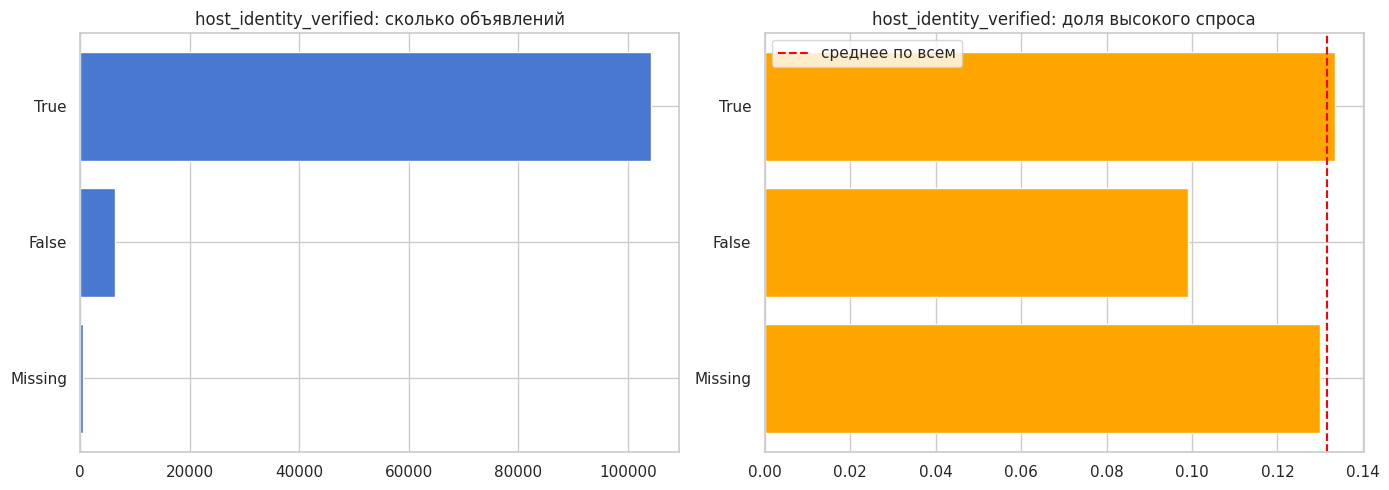

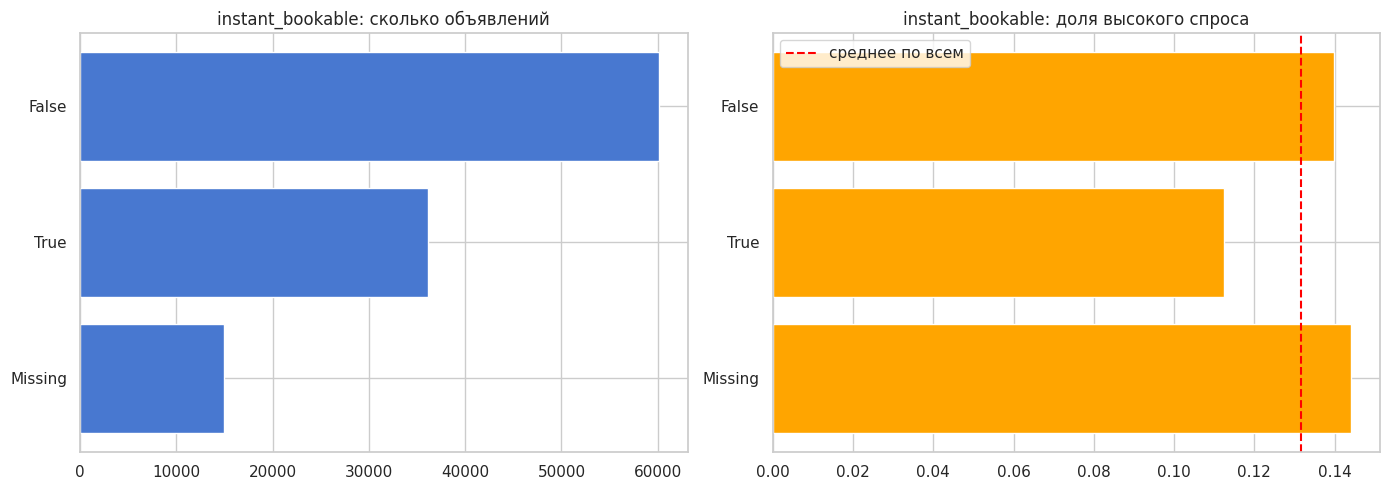

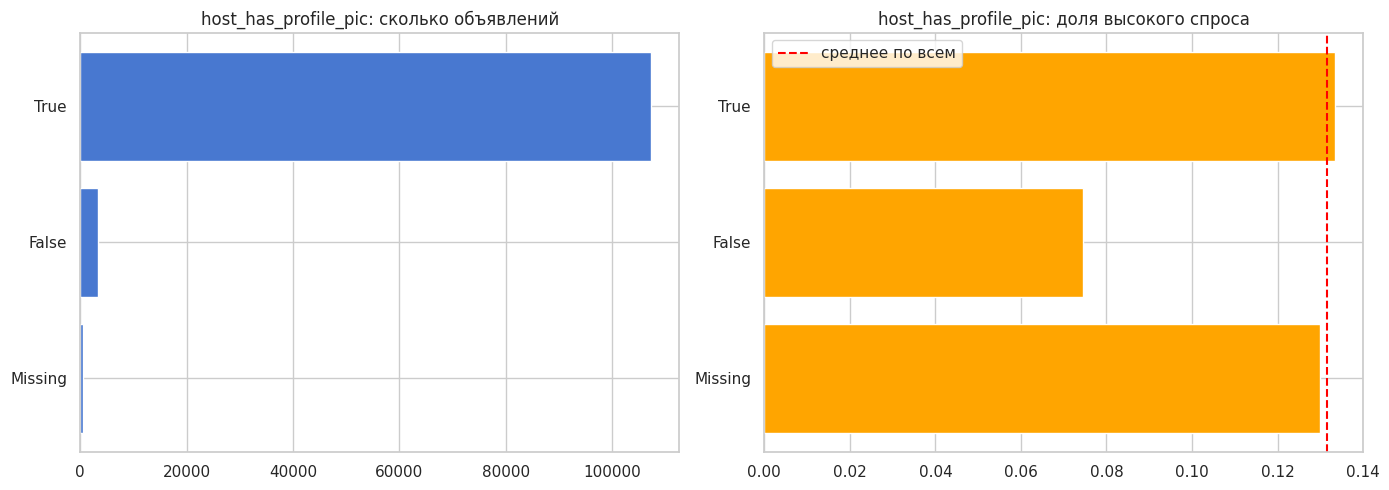

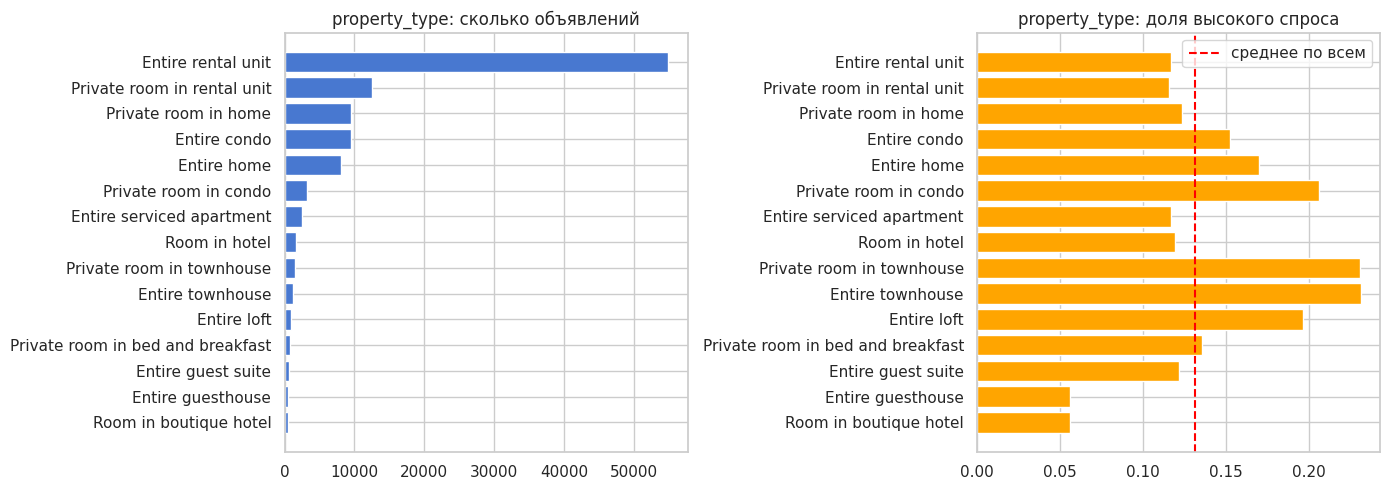

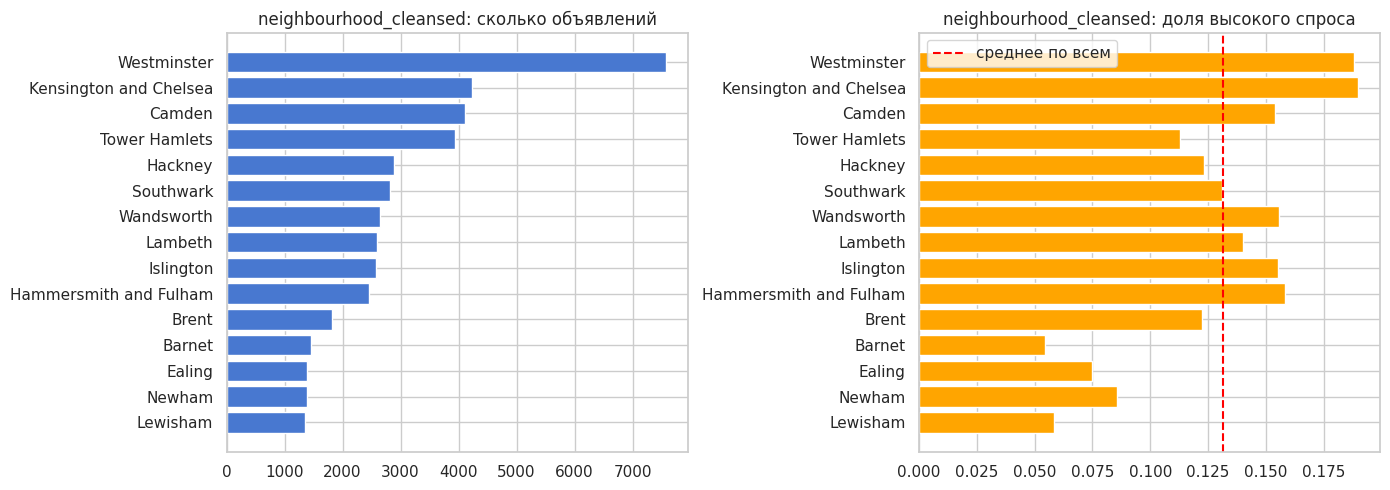

In [80]:
mean_rate = df_final_features['is_high_demand'].mean()

for col in categorical_features + high_card_features:
    # 15 самых частых значений и доля высокого спроса для каждого
    counts = df_final_features[col].value_counts().head(15)
    rate = df_final_features.groupby(col, observed=True)['is_high_demand'].mean().loc[counts.index]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Левый график: сколько объявлений
    axes[0].barh(counts.index.astype(str), counts.values)
    axes[0].set_title(col + ': сколько объявлений')
    axes[0].invert_yaxis()

    # Правый график: доля высокого спроса
    axes[1].barh(rate.index.astype(str), rate.values, color='orange')
    axes[1].axvline(mean_rate, color='red', linestyle='--', label='среднее по всем')
    axes[1].set_title(col + ': доля высокого спроса')
    axes[1].invert_yaxis()
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [81]:
# Типы жилья: оставляем 20 самых частых, остальные называем 'Other'
top_property = df_final_features['property_type'].value_counts().head(20).index
df_final_features['property_type_top'] = (
    df_final_features['property_type'].astype(str)
    .where(df_final_features['property_type'].isin(top_property), 'Other')
)

# Переводим новый столбец в тип category
df_final_features['property_type_top'] = (
    df_final_features['property_type_top'].astype('category')
)

Выводы:

city

Города дают 10–15% высокого спроса (munich=0.10 - toronto=0.157). Цель считается внутри сегмента «город + тип жилья», и «нормальный» уровень, судя по большинству городов, около 10–15%.

Наибольшее количество объявлений в Лондоне

room_type

Целые квартиры (около 79 тыс.) дают около 12,9%, отдельные комнаты (около 31 тыс.) около 13,8%. Гостиничные и общие комнаты (по нескольку сотен) дают 11,8% и 14,6%, но их очень мало.

Различие небольшое: цена, отзывы и рейтинг сравниваются внутри типа жилья, поэтому сам тип почти не влияет.

Слабый признак, но дешёвый. Оставить.

host_response_time

Доля выше у быстро отвечающих хостов: «в течение часа» около 14,4%, «в течение нескольких часов» около 14,8%, «в течение дня» около 10,3%, «несколько дней и больше» около 2,6%. Группа Missing (около 23 тыс., около 21% данных) даёт 11,3%.

Активные хосты получают спрос, а хосты, отвечающие через несколько дней, почти не получают. Missing по доле (11,3%) ближе к «в течение дня» и заметно выше, чем у «несколько дней и больше».

Слабый признак по Phi_K (0,06), но группа «несколько дней и больше» резко отличается от остальных. Оставляем вместе с категорией Missing.

host_is_superhost

Суперхосты дают около 29%, обычные хосты около 6%. Группа Missing около 14%.

Это самое сильное различие среди категориальных признаков.

host_identity_verified

Подтверждённые хосты около 13,3%, неподтверждённые около 9,9%, Missing (около 0,5 тыс.) около 13%.

Слабая связь: у неподтверждённых хостов спрос ниже примерно на 3,5 п.п. Оставляем признак.

instant_bookable False около 14%, True около 11,2%. Missing (около 15 тыс.) около 14,4%.

Мгновенное бронирование связано с высоким спросом слабо: у объявлений с мгновенным бронированием доля чуть ниже. Группа Missing довольно большая (около 13% данных), и в ней доля такая же, как у False. Скорее всего, это строки из выгрузки, где поле не заполнялось.

Слабый признак, но можно оставить.

host_has_profile_pic

У 96% хостов фото есть (около 13,3%). Без фото около 7,4% (около 3% данных), Missing около 13% (очень мало строк).

Различие есть, но затрагивает всего около 3% объявлений, поэтому признак различает мало.

Слабый признак, можно убрать без потери качества.

property_type (15 самых частых)

Самый частый тип, Entire rental unit (около 55 тыс.), и Private room in rental unit дают около 11,6%. Выше среднего: Entire condo около 15%, Private room in condo около 20,5%, Entire townhouse около 23%, Private room in townhouse около 23%. Заметно ниже: Entire guesthouse около 5,6% и Room in boutique hotel около 5,6%.

Оставляем признак, для линейных групп редких типов использовать Other, как в property_type_top.

neighbourhood_cleansed (15 самых частых)

Все 15 районов принадлежат Лондону. Районы дают 5,4–19% (центральные Вестминстер и Кенсингтон и Челси около 19%, Тауэр-Хамлетс около 11%, Хакни около 12%, окраинные Барнет, Льюисем, Илинг и Ньюхэм 5,4–8,5%).

Так как в топ попали только районы Лондона, разница между ними не связана с различиями между городами: она отражает расположение внутри города, например центр Лондона против окраин.

Для Random Forest и LightGBM район проще не использовать. CatBoost может принять его полностью (764 значения).

In [82]:
# преобразуем к типу datetime признаки 'first_review','last_review', 'host_since'
df_final_features[['first_review','last_review', 'host_since']] = df_final_features[['first_review','last_review', 'host_since']].astype('datetime64[ns]')
df_final_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111118 entries, 0 to 111117
Data columns (total 38 columns):
 #   Column                                        Non-Null Count   Dtype         
---  ------                                        --------------   -----         
 0   city                                          111118 non-null  category      
 1   room_type                                     111118 non-null  category      
 2   property_type                                 111118 non-null  category      
 3   first_review                                  111118 non-null  datetime64[ns]
 4   last_review                                   111118 non-null  datetime64[ns]
 5   host_response_time                            111118 non-null  category      
 6   host_is_superhost                             111118 non-null  category      
 7   host_listings_count                           110618 non-null  float64       
 8   host_identity_verified                        111118 n

### 5.3 Корреляционный анализ

**Корреляция между признаками целевой переменной**

In [83]:
# Числовые признаки (и непрерывные, и дискретные счётчики)
interval_cols = [
    'calendar_availability_rate', 'calendar_avg_min_nights', 'avg_recent_comment_len',
    'host_listings_count', 'host_total_listings_count',
    'minimum_nights', 'maximum_nights', 'availability_eoy',
    'accommodates', 'bedrooms', 'beds', 'bathrooms',
    'host_response_rate', 'host_acceptance_rate'
]

# Категориальные признаки и цель
categorical_cols = [
    'is_high_demand', 'city', 'room_type', 'property_type_top', 'host_response_time',
    'host_is_superhost', 'host_identity_verified', 'instant_bookable'
]

features_for_corr = interval_cols + categorical_cols
df_sample = df_final_features[features_for_corr].sample(n=20000, random_state=42)

corr_matrix = df_sample.phik_matrix(interval_cols=interval_cols)

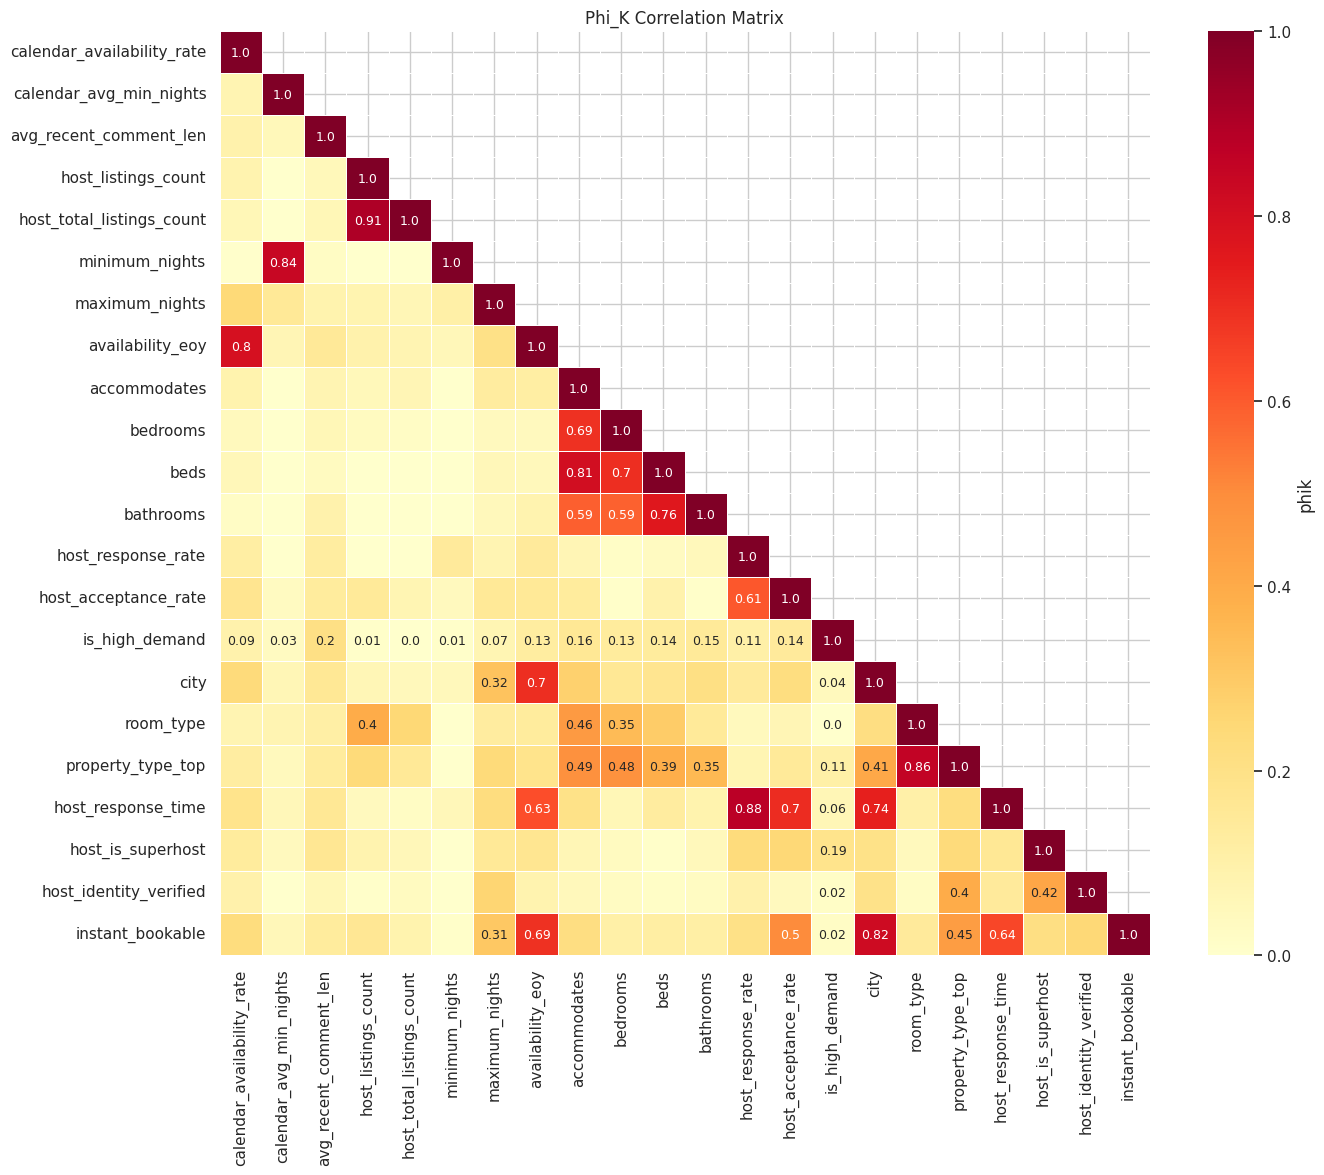

In [84]:
plt.figure(figsize=(15, 12))

labels = corr_matrix.round(2).astype(str).where(corr_matrix >= 0.3, '')

# Для цели показываем все значения
labels.loc['is_high_demand'] = corr_matrix.loc['is_high_demand'].round(2).astype(str)
labels['is_high_demand'] = corr_matrix['is_high_demand'].round(2).astype(str)

# Прячем верхний треугольник (матрица симметрична)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(corr_matrix, mask=mask, annot=labels, fmt='',
            cmap='YlOrRd', vmin=0, vmax=1,
            annot_kws={'size': 9}, linewidths=0.5,
            cbar_kws={'label': 'phik'})
plt.title('Phi_K Correlation Matrix')
plt.show()

In [85]:
# Корреляции целевой переменной is_high_demand с признаками
phik_click_correlations_all = (corr_matrix['is_high_demand'].drop('is_high_demand'))
phik_click_correlations_all.sort_values(ascending=False)

,is_high_demand
avg_recent_comment_len,0.203182
host_is_superhost,0.186273
accommodates,0.159604
bathrooms,0.147679
host_acceptance_rate,0.141645
beds,0.136204
bedrooms,0.133041
availability_eoy,0.125734
host_response_rate,0.108976
property_type_top,0.108869


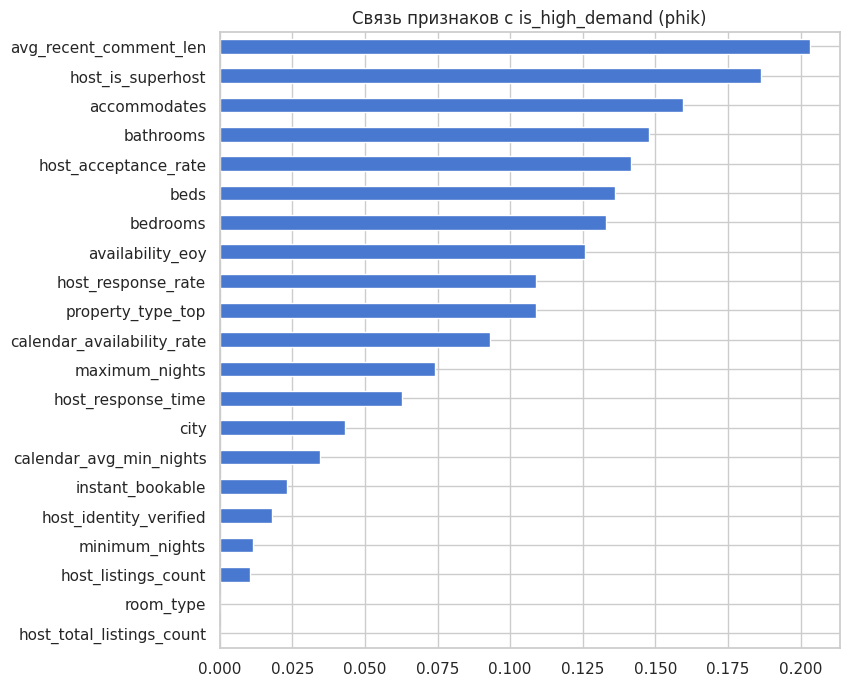

In [86]:
target_corr = corr_matrix['is_high_demand'].drop('is_high_demand').sort_values()
target_corr.plot(kind='barh', figsize=(8, 8), title='Связь признаков с is_high_demand (phik)')
plt.show()

1. Анализ мультиколинеарности

Для оценки взаимосвязей между признаками использована матрица Phi_K (диапазон 0–1, учитывает нелинейные связи и работает с числовыми и категориальными признаками одновременно). Расчёт сделан на случайной выборке из 20 000 строк.

Пары признаков с очень высокой связью (0,8 и выше):

Пара признаков	Phi_K

room_type и property_type_top	0,86	Оставляем оба: property_type_top детальнее, но это не независимая информация

host_response_rate и host_response_time	0,88	Оставляем host_response_time, так как в нём есть категория Missing

calendar_avg_min_nights и minimum_nights	0,84	Оставляем minimum_nights, calendar_avg_min_nights удаляем

host_listings_count и host_total_listings_count	0,91	Оставляем один (host_total_listings_count)

calendar_availability_rate и availability_eoy	0,80	Оставляем calendar_availability_rate, так как это доля, она меньше зависит от даты выгрузки

accommodates и beds	0,81	Пока оставляем оба, значимость проверим на модели

Умеренная связь (0,5–0,79).

Признаки размера жилья (accommodates, bedrooms, beds, bathrooms) связаны между собой на уровне 0,59–0,81. Это ожидаемо: чем больше людей вмещает жильё, тем больше в нём спален, кроватей и ванных. Такие признаки оставляем.

Общий фактор: город. Признак city сильно связан с instant_bookable (0,82), availability_eoy (0,70) и host_response_time (0,74). Это указывает, что часть признаков отражает особенности выгрузки данных по городам, а не только свойства самих объявлений.

Вывод. Мультиколинеарность в данных присутствует, но она умеренная и в основном объясняется очевидными причинами (один и тот же показатель в разных вариантах). Для моделей на деревьях (Random Forest, LightGBM, CatBoost) такая связь не мешает качеству прогноза, но искажает интерпретацию важности признаков. Поэтому из набора признаков удаляем явные дубли: calendar_avg_min_nights, calendar_avg_max_nights, availability_eoy, host_response_rate и host_listings_countи calculated_host_listings_count (не входил в матрицу Phi_K_.

2. Анализ связи с целевой переменной

Связь признаков с is_high_demand по Phi_K умеренная: максимальные значения составляют 0,19–0,20. Для несбалансированной цели (доля положительного класса около 13%) такие значения означают заметную, но не сильную связь.

Самая сильная связь (0,19–0,20):

avg_recent_comment_len;

host_is_superhost (суперхосты дают около <..>% высокого спроса против <..>% у остальных).

Заметная связь (0,11–0,16):

availability_eoy: объявления с закрытым календарём дают около <..>% высокого спроса против 13% в среднем;

host_acceptance_rate и host_response_rate (чем быстрее отвечает хост, тем выше доля);

accommodates (доля растёт с вместимостью), bathrooms, bedrooms, beds и property_type_top.

Слабая связь (меньше 0,1): calendar_availability_rate, maximum_nights, minimum_nights, room_type, host_response_time, host_identity_verified, host_listings_count, host_total_listings_count, instant_bookable, city (доля высокого спроса по городам различается слабо: от около 10,5% в Мюнхене до около 15,7% в Торонто).

Вывод: Ни один признак по отдельности не объясняет целевую переменную полностью, поэтому для прогноза нужна комбинация признаков. Окончательный отбор признаков выполняется по качеству моделей (PR-AUC на кросс-валидации), а не только по значениям Phi_K.

In [87]:
# удаляем bathrooms_text, уже использовали его для заполнения пропусков в bathrooms
df_final_features = df_final_features.drop(columns=['bathrooms_text'])

In [88]:
# Убираем мультиколлинеарные признаки calendar_avg_min_nights, calendar_avg_max_nights, availability_eoy, host_response_rate и calculated_host_listings_count, host_listings_count
df_final_features.drop(columns=['calendar_avg_max_nights', 'calendar_avg_min_nights', 'availability_eoy','host_response_rate','calculated_host_listings_count','host_listings_count'], inplace=True)

In [89]:
# также удаляем neighbourhood_cleansed (слабый признак) и property_type (заменен на property_type_top)
df_final_features.drop(columns=['neighbourhood_cleansed','property_type'], inplace=True)

In [90]:
df_final_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111118 entries, 0 to 111117
Data columns (total 29 columns):
 #   Column                                        Non-Null Count   Dtype         
---  ------                                        --------------   -----         
 0   city                                          111118 non-null  category      
 1   room_type                                     111118 non-null  category      
 2   first_review                                  111118 non-null  datetime64[ns]
 3   last_review                                   111118 non-null  datetime64[ns]
 4   host_response_time                            111118 non-null  category      
 5   host_is_superhost                             111118 non-null  category      
 6   host_identity_verified                        111118 non-null  category      
 7   minimum_nights                                111104 non-null  float64       
 8   maximum_nights                                111087 n

### 5.4 Текстовые данные

Изучите названия листингов `name` и отзывы `reviews`. Сформулируйте гипотезы о том, какие текстовые признаки стоит создать.

In [91]:
# все текстовые object признаки
text_features = df_final_features.select_dtypes(include='object').columns.to_list()
text_features

['amenities', 'name', 'concat_recent_comments']

In [92]:
# считаем общее количество удобств в каждом объявлении
df_final_features['amenities_count'] = df_final_features['amenities'].str.split(',').str.len()

# удаляем изанчальный столбец amenities
df_final_features.drop(columns=['amenities'], inplace=True)

In [93]:
df_final_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111118 entries, 0 to 111117
Data columns (total 29 columns):
 #   Column                                        Non-Null Count   Dtype         
---  ------                                        --------------   -----         
 0   city                                          111118 non-null  category      
 1   room_type                                     111118 non-null  category      
 2   first_review                                  111118 non-null  datetime64[ns]
 3   last_review                                   111118 non-null  datetime64[ns]
 4   host_response_time                            111118 non-null  category      
 5   host_is_superhost                             111118 non-null  category      
 6   host_identity_verified                        111118 non-null  category      
 7   minimum_nights                                111104 non-null  float64       
 8   maximum_nights                                111087 n

**Выполняем  обработку текста в признаке df_final_features['concat_recent_comments']**

**Шаги:**

1. Импортировать библиотеку nltk и скачать стоп-слова для русского языка, и создать множество со стоп-словами.

2. Перевести весь текст в нижний регистр с помощью функции lower().

3. Удалить из текстов все специальные символы и лишние пробелы с помощью регулярного выражения.

4. Удалить из текстов все переносы строк с помощью функции strip().

5. Разделить текст на токены с помощью метода split() без аргументов. В этом случае разделителями будут любые последовательности пробельных символов.

In [94]:
# 1. Скачиваем стоп-слова
nltk.download('stopwords')
languages = ['english', 'french', 'german', 'spanish', 'dutch', 'italian', 'portuguese', 'russian']

multilingual_stopwords = set()
for lang in languages:
    try:
        multilingual_stopwords.update(stopwords.words(lang))
    except OSError:
        pass

# 2. Функция безопасной токенизации и очистки одной строки
def process_text(text):
    if not isinstance(text, str) or not text.strip():
        return []

    # Нижный регистр
    text = text.lower()

    # Удаление спецсимволов и лишних пробелов
    text = re.sub(r'[^\w\s]', ' ', text) # убираем пунктуацию
    text = re.sub(r'\s+', ' ', text).strip() # убираем дублирующиеся пробелы

    # Разбиение на токены
    tokens = text.split()

    # Фильтрация стоп-слов
    filtered_tokens = [w for w in tokens if w not in multilingual_stopwords]

    return filtered_tokens

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [95]:
# 3. Применяем единую функцию к столбцу
df_final_features['tokens_comments'] = df_final_features['concat_recent_comments'].fillna('').apply(process_text)

# 4. Объединяем обратно в очищенную строку (если нужно для TF-IDF или CountVectorizer)
df_final_features['filtered_sentences'] = df_final_features['tokens_comments'].apply(lambda x: " ".join(x))

In [96]:
# Считаем количество строк, где реально получились токены
has_tokens = df_final_features['tokens_comments'].apply(lambda x: len(x) > 0)

print(f"Всего строк с токенами: {has_tokens.sum()}")
print(f"Строк без отзывов / только со стоп-словами: {(~has_tokens).sum()}")

# Выводим первые 5 строк, где токены НЕ пустые
df_final_features[has_tokens][['concat_recent_comments', 'tokens_comments']].head()

Всего строк с токенами: 91531
Строк без отзывов / только со стоп-словами: 19587


,concat_recent_comments,tokens_comments
0,We loved staying on the boat. The space was co...,"[loved, staying, boat, space, cozy, comfy, ent..."
1,Edwin was very nice and the room was amazing. ...,"[edwin, nice, room, amazing, 100, recommendati..."
2,Edwin war super freundlich und die Unterkunft ...,"[edwin, super, freundlich, unterkunft, perfekt..."
3,We loved our stay! The location was perfect an...,"[loved, stay, location, perfect, space, ideal,..."
4,"The location was perfect, with everything we n...","[location, perfect, everything, needed, close,..."


In [97]:
# Применяем единую функцию к столбцу name
df_final_features['tokens_name'] = df_final_features['name'].fillna('').apply(process_text)

# Объединяем обратно в очищенную строку (если нужно для TF-IDF или CountVectorizer)
df_final_features['filtered_name'] = df_final_features['tokens_name'].apply(lambda x: " ".join(x))

In [98]:
# удаляем столбцы
df_final_features = df_final_features.drop(columns=['tokens_comments', 'tokens_name', 'concat_recent_comments', 'name'], errors='ignore')

In [99]:
df_final_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111118 entries, 0 to 111117
Data columns (total 29 columns):
 #   Column                                        Non-Null Count   Dtype         
---  ------                                        --------------   -----         
 0   city                                          111118 non-null  category      
 1   room_type                                     111118 non-null  category      
 2   first_review                                  111118 non-null  datetime64[ns]
 3   last_review                                   111118 non-null  datetime64[ns]
 4   host_response_time                            111118 non-null  category      
 5   host_is_superhost                             111118 non-null  category      
 6   host_identity_verified                        111118 non-null  category      
 7   minimum_nights                                111104 non-null  float64       
 8   maximum_nights                                111087 n

**Выводы:**

Текстовые столбцы типа object:

* удобства (amenities),  
* объявленич (name),
* отзывы за последний год (concat_recent_comments).


* Из списка удобств создан числовой признак amenities_count (число удобств в объявлении).
Подсчёт выполнен по запятым, поэтому он приблизительный. Исходный столбец amenities удалён.

* Для отзывов и названий применена единая функция очистки: приведение к нижнему регистру, удаление пунктуации и лишних пробелов, токенизация по пробелам, удаление стоп-слов.

* Результат сохранён в очищенных строках filtered_sentences и filtered_name

* Промежуточные столбцы со списками токенов и исходные тексты (concat_recent_comments, name) удалены, чтобы не занимать память и не попадать в модели.

* Особенности текстов:
  * Отзывы многоязычные (английский, немецкий, французский и др.), поэтому использованы стоп-слова восьми языков, а не только русского.

* Решение для моделирования:
  * filtered_sentences и filtered_name используются в Random Forest и LightGBM через TF-IDF с ограниченным числом признаков, а в CatBoost как текстовые признаки.

### 5.5 Итоги EDA

Зафиксируйте ключевые наблюдения и план по созданию новых признаков.

**Ключевые наблюдения:**
* Очистка и преобразования:

Заглушка 2 147 483 647 в maximum_nights и calendar_avg_max_nights заменена на пропуск; экстремальные значения минимального срока (minimum_nights_avg_ntm) обрезаны на 400 (кластер около 365 сохранён).
Пропуски в bathrooms (1403) восстановлены из bathrooms_text (осталось 55).
Булевы и категориальные признаки приведены к category с категорией Missing; проценты хоста переведены в числа; редкие типы жилья объединены в property_type_top.
Из текстов созданы amenities_count, filtered_sentences и filtered_name; исходные тексты удалены.
Удалены дублирующие и слабые признаки: calendar_avg_min_nights, calendar_avg_max_nights, availability_eoy, host_response_rate, host_listings_count, neighbourhood_cleansed, property_type, bathrooms_text.

* Главные закономерности.

Сильнее всего с высоким спросом связаны host_is_superhost (около 29% против 6% у остальных хостов), avg_recent_comment_len, вместимость и размер жилья (accommodates, bathrooms, beds, bedrooms), доступность календаря и минимальный срок.

Скорость ответа хоста различает группы по долям (при ответе «в течение нескольких дней и больше» около 2,6% против 14–15% при ответе в течение часа или нескольких часов).

Городи room_type связаны с целью слабо.
Мультиколинеарность умеренная и объясняется дублями одного показателя (удалены).


* Гипотезы для feature engineering.

  - стаж хоста по host_since, дни с последнего отзыва и длительность истории отзывов по first_review и last_review;
  - флаги закрытого календаря и долгой аренды;
  - отношения вместимости к числу спален и ванных.

## 6.Обработка пропусков (если необходимо)

Обработайте пропуски согласно стратегии, выработанной в результате EDA. Все решения обоснуйте.

In [100]:
df_final_features.isna().sum()

,0
city,0
room_type,0
first_review,0
last_review,0
host_response_time,0
host_is_superhost,0
host_identity_verified,0
minimum_nights,14
maximum_nights,31
instant_bookable,0


**Стратегия обработки пропусков:**

Оставшиеся пропуски в таблице не заполнялись и не удалялись.

Большая часть пропусков (avg_recent_comment_len, host_acceptance_rate, host_since, host_total_listings_count, beds, bedrooms, calendar_availability_rate) отражает отсутствие события или данных (нет отзывов, нет истории хоста, не заполнено описание), поэтому сам пропуск несёт информацию о целевой переменной.

Заполнение средним или медианой убрало бы этот сигнал.

Для LightGBM и CatBoost пропуски передаются как есть, для Random Forest используется заполнение константой -1 внутри пайплайна, которое отличает «нет значения» от настоящих значений.

Единичные пропуски (minimum_nights, maximum_nights, bathrooms, меньше 0,2%) заполняются медианой внутри пайплайна. Все статистики для заполнения считаются только по обучающей выборке, чтобы избежать утечки данных.

Кроме строк с пропусками в компонентах таргета (раздел 3), строки не удалялись.

| Колонка | % пропусков | Стратегия | Обоснование |
|---------|------------|-----------|-------------|
| `avg_recent_comment_len` | 17,6% (19 515) | Оставить `NaN` (LightGBM, CatBoost); в Random Forest заполнение -1 внутри пайплайна | Нет отзывов за последний год, пропуск означает отсутствие активности. Среднее или медиана выдумали бы отзывы; пропуск связан с целью |
| `host_acceptance_rate` | 17,5% (19 407) | Оставить `NaN`; в Random Forest -1 | У хоста нет истории бронирований. Заполнение средним сделало бы «новых» хостов похожими на опытных |
| `beds` | 1,4% (1 501) | Оставить `NaN`; в Random Forest -1 | Медиана убрала бы этот сигнал |
| `host_since`, `host_total_listings_count` | 13,6% (15 142) | Оставить `NaN`; в Random Forest -1 | Одинаковое число пропусков означает один блок строк без сведений о хосте (вероятно, часть выгрузки). Пропуск несёт информацию, заполнение её уничтожило бы |
| `calendar_availability_rate` | 17,0% (18 864) | Оставить `NaN`; в Random Forest -1 | Нет данных календаря|
| `bedrooms` | 0,6% (670) | Оставить `NaN`; в Random Forest -1 | Количество спален не указано (возможно, у студий). Медиана 1 исказила бы эту группу |
| `bathrooms` | 0,05% (55) | в Random Forest -1 | Основная часть восстановлена из `bathrooms_text` (было 1 403, осталось 55) |
| `maximum_nights` | 0,03% (31) | в Random Forest -1 | Единичные пропуски; часть появилась после замены заглушки 2 147 483 647 на `NaN` |
| `minimum_nights` | 0,01% (14) | в Random Forest -1 | случайные пропуски |

## 7.Feature Engineering (если необходимо)

Создайте новые признаки, обоснованные EDA.

In [101]:
# Признаки по датам
# Точка отсчёта: последний отзыв в данных каждого города
ref_date = df_final_features.groupby('city', observed=True)['last_review'].transform('max')

df_final_features['days_since_last_review'] = (ref_date - df_final_features['last_review']).dt.days
df_final_features['review_span_days'] = (df_final_features['last_review'] - df_final_features['first_review']).dt.days
df_final_features['host_tenure_days'] = (ref_date - df_final_features['host_since']).dt.days

# Флаги
# Календарь закрыт весь год (если данных нет, оставляем пропуск, а не 0)
df_final_features['calendar_closed'] = (df_final_features['calendar_availability_rate'] == 0).astype(float)
df_final_features.loc[df_final_features['calendar_availability_rate'].isna(), 'calendar_closed'] = np.nan

# Долгая аренда: минимум от 28 ночей
df_final_features['is_long_stay'] = (df_final_features['minimum_nights'] >= 28).astype(int)

# Отношения вместимости
# Студия (0 спален) считается как 1, нулевое число ванных заменяем на пропуск
df_final_features['guests_per_bedroom'] = df_final_features['accommodates'] / df_final_features['bedrooms'].clip(lower=1)
df_final_features['guests_per_bathroom'] = df_final_features['accommodates'] / df_final_features['bathrooms'].replace(0, np.nan)

In [102]:
# удаляем first_review и last_review, host_since,city
df_final_features.drop(columns=['first_review', 'last_review','host_since','city'], inplace=True)

In [103]:
df_final_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111118 entries, 0 to 111117
Data columns (total 32 columns):
 #   Column                                        Non-Null Count   Dtype   
---  ------                                        --------------   -----   
 0   room_type                                     111118 non-null  category
 1   host_response_time                            111118 non-null  category
 2   host_is_superhost                             111118 non-null  category
 3   host_identity_verified                        111118 non-null  category
 4   minimum_nights                                111104 non-null  float64 
 5   maximum_nights                                111087 non-null  float64 
 6   instant_bookable                              111118 non-null  category
 7   accommodates                                  111118 non-null  float64 
 8   bedrooms                                      110448 non-null  float64 
 9   beds                                 

**Созданные признаки и обоснование:**

| Исходный признак(и) | Созданный признак | Тип | Логика и формула | Обоснование решения |
| --- | --- | --- | --- | --- |
| `last_review` | `days_since_last_review` | Числовой, дискретный (дни) | `max(last_review) по городу − last_review`. | Показывает «свежесть» активности листинга. Опорная дата берётся по городу, потому что срезы данных могут различаться. Это косвенный прокси активности, поэтому нужна проверка на утечку (ablation). |
| `first_review`, `last_review` | `review_span_days` | Числовой, дискретный (дни) | `last_review − first_review` | Отражает, как долго листинг получает отзывы. Это возраст листинга на рынке, а не число отзывов. Признак тоже требует проверки на косвенную утечку. |
| `host_since`, `last_review` (опорная дата по городу) | `host_tenure_days` | Числовой, дискретный (дни) | `max(last_review) по городу − host_since` | Стаж хозяина заменяет исходную дату, которую модель не может использовать напрямую. Опытные хозяева обычно лучше управляют листингом. |
| `calendar_availability_rate` | `calendar_closed` | Бинарный (0/1, NaN сохранён) | `1`, если `calendar_availability_rate == 0`, иначе `0`. Если исходное значение NaN, результат тоже NaN | Закрытый календарь означает, что листинг фактически не сдаётся, и в таких листингах доля целевого класса около 1%. Деревья могли бы найти порог сами, но явный флаг делает правило прозрачнее. NaN сохранён, чтобы не выдавать пропуск за «открытый». |
| `minimum_nights` | `is_long_stay` | Бинарный (0/1) | `1`, если `minimum_nights ≥ 28`, иначе `0` | Листинги с долгим минимальным сроком (месяц и больше) работают по другой модели аренды, и доля целевого класса в них 1–2%. Флаг выделяет этот сегмент и снижает влияние выбросов в `minimum_nights`. |
| `accommodates`, `bedrooms` | `guests_per_bedroom` | Числовой, непрерывный | `accommodates / bedrooms.clip(lower=1)` | Отношение показывает плотность размещения. Деревья плохо строят отношения признаков сами. `clip(lower=1)` защищает от деления на 0 для студий. |
| `accommodates`, `bathrooms` | `guests_per_bathroom` | Числовой, непрерывный | `accommodates / bathrooms.replace(0, NaN)` | Показывает комфорт и нагрузку на санузел. Нулевое значение заменяется на NaN, чтобы не получить бесконечность. Пропуски в `bathrooms` информативны, поэтому остаются NaN. |
| `amenities` | `amenities_count` | Числовой, дискретный | `amenities.str.split(',').str.len()`. Исходный столбец удалён | Число удобств — компактная мера оснащённости, вместо сырой строки со списком. Подсчёт приблизительный, потому что запятые внутри названий считаются как разделители. |
| `property_type` | `property_type_top` | Категориальный | Топ-20 типов остаются как есть, остальные заменяются на `Other` | Редкие категории дают шум и переобучение, а таблица становится разреженной. Топ-20 сохраняет основную информацию при небольшом числе категорий. |
| `name` | `filtered_name` | Текстовый | Очистка текста и удаление стоп-слов на 8 языках (NLTK). Исходный текст удалён | В названии содержатся слова-маркеры, например расположение и тип жилья. Многоязычные стоп-слова нужны, потому что данные включают 10 городов с разными языками. Признак используется через TF-IDF (RF, LightGBM) или `text_features` (CatBoost). |
| `concat_recent_comments` | `filtered_sentences` | Текстовый | Та же функция `process_text`, что и для названия. Исходный текст и списки токенов удалены | Текст отзывов отражает впечатление гостей. Признак относится к группе косвенных прокси активности и требует проверки в ablation. |



* Обоснование удаления исходных и промежуточных столбцов

По результатам генерации новых признаков из датасета были **удалены следующие столбцы**:

`first_review`,`last_review`,`host_since`,`city`:

* *Причина:* Деревья решений не умеют эффективно использовать сырые значения `datetime`. Вся полезная информация полностью перенесена в числовые признаки.


* Готовность признакового пространства к обучению моделей

* **Совместимость типов данных:** Все категориальные признаки (`host_response_time`, `host_is_superhost`, `host_identity_verified`, `instant_bookable`, `property_type_top`) приведены к единому формату `category`, что позволяет **LightGBM** и **CatBoost** обрабатывать их без дополнительного ручного One-Hot кодирования.

* **Текстовый вектор:** Признаки `filtered_sentences`,`filtered_name` сохранены в формате чистой строки, что гарантирует поддержку как встроенными механизмами `CatBoostClassifier`, так и стандартным `TfidfVectorizer` для `RandomForest` / `LightGBM`.


## 8.Кодирование и масштабирование (если необходимо)

Закодируйте категориальные признаки. Примените масштабирование там, где оно нужно. Объясните, для каких моделей необходимы такие преобразования и почему.

1. Теоретическое обоснование необходимости преобразований

| Семейство моделей | Требуется ли кодирование категорий? | Требуется ли масштабирование (Scaling)? | Почему? / Обоснование |
| --- | --- | --- | --- |
| **CatBoost** | **Нет** (ручное не требуется) | **Нет** | Нативно обрабатывает `category` с помощью встроенного Target Encoding (Ordered Target Statistics). Деревья решений инвариантны к масштабу числовых признаков. |
| **LightGBM** | **Нет** (ручное не требуется) | **Нет** | Встроена нативная поддержка `category` (поиск оптимального бинарного разбиения по категориям через гистограммы). Инвариантен к монотонным преобразованиям и масштабу. |
| **Random Forest** *(scikit-learn)* | **Да** (One-Hot или Ordinal Encoding) | **Нет** | Реализация `Random Forest` в `scikit-learn` **не поддерживает** тип `category` и строки нативно. Однако масштабирование фичей не нужно, так как сплиты опираются только на порядок значений. |


---

2. Выводы для раздела отчета

  - **Масштабирование признаков (MinMaxScaler / StandardScaler):**
  * **Не требуется.** Все выбранные модели (**Random Forest**, **CatBoost**, **LightGBM**) являются **алгоритмами с использованием деревьев решений (Tree-based models)**. Для построения предикатов в узлах деревьев используется логика сравнения (пороговые значения), поэтому монотонные линейные преобразования и масштаб признаков не влияют на качество разбиения и метрики моделей.


  - **Кодирование категориальных признаков (Categorical Encoding):**
    
    * **Для CatBoost:** Ручное кодирование (OHE) **вредно и не требуется**. Категориальные признаки должны быть типа str

    * **Для LightGBM:**  Категориальные признаки приведены в формат `pandas.DataFrame` `category`.необходимо применить **OrdinalEncoder** к категориям и **TfidfVectorizer** к текстовым признакам.
    
    * **Для Random Forest и TF-IDF текста:** Поскольку `Random Forest` из `scikit-learn`  необходимо применить **OrdinalEncoder** к категориям и **TfidfVectorizer** к текстовым признакам.



3. Практическая реализация в коде

Поскольку подходы к данным различаются для бустингов и для Random Forest, создадим два пайплайна подготовки данных

4. Итоговая сводка:

| Модель | Кодирование категорий | Векторизация текста | Масштабирование (Scaling) |
| --- | --- | --- | --- |
| **CatBoostClassifier** | Нативное (`cat_features` текствые) | Нативная (`text_features=['filtered_sentences']`) | **Не применимо** |
| **LGBMClassifier** | OrdinalEncoder (`categorical_feature`) | Предварительный `TfidfVectorizer` | **Не применимо** |
| **DecisionTreeClassifier** | OrdinalEncoder | Предварительный `TfidfVectorizer` | **Не применимо** |

In [104]:
target = 'is_high_demand'

categorical_features = ['room_type', 'host_response_time', 'host_is_superhost',
                        'host_identity_verified', 'instant_bookable', 'host_has_profile_pic',
                        'property_type_top']
text_features = ['filtered_sentences', 'filtered_name']

# Все остальные столбцы - числовые признаки
numeric_features = [c for c in df_final_features.columns
                    if c not in categorical_features + text_features + [target]]

print(len(numeric_features), len(categorical_features), len(text_features))

# Проверка, что нет бесконечных значений
print((df_final_features[numeric_features] == float('inf')).sum().sum())      # ожидаем 0

22 7 2
0


In [105]:
# TF-IDF не принимает NaN: пропуск в тексте = пустая строка
for c in text_features:
    df_final_features[c] = df_final_features[c].fillna('')

##### Препроцессор для Random Forest (rf_preprocessor)

In [106]:
# Random Forest
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features),
        ('text_sent', TfidfVectorizer(max_features=100), 'filtered_sentences'),
        ('text_name', TfidfVectorizer(max_features=100), 'filtered_name'),
        ('num', SimpleImputer(strategy='constant', fill_value=-1), numeric_features)
    ],
    remainder='drop',
    sparse_threshold=0
)

##### Препроцессор для LightGBM (lgbm_preprocessor)

In [107]:
# LightGBM: NaN в числовых обрабатывает сам
lgbm_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features),
        ('text_sent', TfidfVectorizer(max_features=100), 'filtered_sentences'),
        ('text_name', TfidfVectorizer(max_features=100), 'filtered_name'),
        ('num', 'passthrough', numeric_features)
    ],
    remainder='drop',
    sparse_threshold=0
)

Препроцессор для CatBoost (catboost_preprocessor) не требуется

**Решения по кодированию и масштабированию:**

Масштабирование не применяется. Все модели древовидные (Random Forest, LightGBM, CatBoost) и не зависят от масштаба признаков.

* Категории.

Для Random Forest и LightGBM используется OrdinalEncoder.

Для LightGBM кодированные колонки дополнительно передаются как категориальные (categorical_feature), чтобы порядок кодов не воспринимался как числовой. Неизвестные категории получают код -1.

CatBoost работает с категориями нативно, ручное кодирование не нужно.

* Текст. TfidfVectorizer(max_features=100) отдельно для каждого текстового признака (Random Forest, LightGBM).

Для CatBoost используется нативный text_features. Пропуски в тексте заменяются пустой строкой.

* Пропуски в числовых признаках.

Для Random Forest, LightGBM они заполняются значением -1 как явным маркером «нет данных» (например, нет отзывов или календаря).

 CatBoost оставляем NaN - обрабатывает их нативно.

Препроцессоры только объявлены. fit выполняется строго на обучающей выборке, в кросс-валидации внутри Pipeline отдельно на каждом фолде. Так статистики не утекают из валидации и теста.

## 9.Деление на выборки

Разделите данные на обучающую и тестовую выборки. Обоснуйте пропорции и стратегию разделения.

Т.к. присутствует дисбаланс классов целевой переменной используем stratify

In [108]:
# выделяем целевую переменную и признаки
X = df_final_features.drop(columns=['is_high_demand'])
y = df_final_features['is_high_demand']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    test_size=0.2,
    random_state=42
)

In [109]:
X_train.shape

(88894, 31)

In [110]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 88894 entries, 84359 to 79775
Data columns (total 31 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   room_type                                     88894 non-null  category
 1   host_response_time                            88894 non-null  category
 2   host_is_superhost                             88894 non-null  category
 3   host_identity_verified                        88894 non-null  category
 4   minimum_nights                                88883 non-null  float64 
 5   maximum_nights                                88868 non-null  float64 
 6   instant_bookable                              88894 non-null  category
 7   accommodates                                  88894 non-null  float64 
 8   bedrooms                                      88348 non-null  float64 
 9   beds                                          87684

In [111]:
X_test.shape

(22224, 31)

In [112]:
y_train.shape

(88894,)

In [113]:
y_test.shape

(22224,)

**Параметры разбивки и обоснование:**

* Итоговый датасет объёмом 111118 объекта разделён на обучающую (80%, ≈ 88894) и тестовую (20%, ≈ 22224) выборки. Объёма обучающей выборки достаточно для устойчивого обучения ансамблевых моделей (CatBoost, LightGBM, Random Forest), а тестовая выборка достаточно велика для оценки метрик.

* Разбиение выполнено методом стратифицированного случайного сплита (`stratify=y`) с зафиксированным `random_state=42` для воспроизводимости. Стратификация сохраняет долю класса 1 в обоих подмножествах.

## 10.Сохранение готового датасета
Сохраните готовый датасет, используя библиотеку joblib.

In [114]:
# для inference загружаем обработанные данные в S3
# из .env
extras = {
    "bucket": os.getenv("S3_BUCKET"),
    "endpoint_url": os.getenv("S3_ENDPOINT_URL"),
    "aws_access_key_id": os.getenv("AWS_ACCESS_KEY_ID"),
    "aws_secret_access_key": os.getenv("AWS_SECRET_ACCESS_KEY"),
}

s3 = boto3.client(
    "s3",
    aws_access_key_id=extras.get("aws_access_key_id"),
    aws_secret_access_key=extras.get("aws_secret_access_key"),
    endpoint_url=extras.get("endpoint_url"),
)

BUCKET = extras["bucket"]
DATA_KEY = "smartscore/data/processed_data.joblib"          # данные для обучения
MODEL_PREFIX = "models/high_demand_catboost/v1/"

In [115]:
# Формируем словарь со всеми готовыми объектами
processed_data = {
    'X_train': X_train,
    'X_test': X_test,
    'y_train': y_train,
    'y_test': y_test,
    'categorical_features': categorical_features,
    'numeric_features': numeric_features,
    'text_feature': text_features,
    'rf_preprocessor': rf_preprocessor,       # Необученный
    'lgbm_preprocessor': lgbm_preprocessor   # Необученный
}

# упаковываем в память и сразу отправляем в S3
buffer = io.BytesIO()
joblib.dump(processed_data, buffer, compress=3)
buffer.seek(0)
s3.upload_fileobj(buffer, BUCKET, DATA_KEY)

# проверка: файл действительно появился
info = s3.head_object(Bucket=BUCKET, Key=DATA_KEY)
print("Загружено в S3:", DATA_KEY, "| размер, МБ:", round(info["ContentLength"] / 1e6, 1))

Загружено в S3: smartscore/data/processed_data.joblib | размер, МБ: 46.1


для inference:

In [116]:
artifacts = {
    "top_property_types": [t for t in X_train["property_type_top"].unique() if t != "Other"],
    "stopwords": sorted(multilingual_stopwords),
}
with open("preprocess_artifacts.json", "w", encoding="utf-8") as f:
    json.dump(artifacts, f, ensure_ascii=False)

# проверка: что попало в файл
print("Типов жилья в топе:", len(artifacts["top_property_types"]))
print("Стоп-слов:", len(artifacts["stopwords"]))

Типов жилья в топе: 20
Стоп-слов: 1501


In [117]:
extras = {
    "bucket": os.getenv("S3_BUCKET"),
    "endpoint_url": os.getenv("S3_ENDPOINT_URL"),
    "aws_access_key_id": os.getenv("AWS_ACCESS_KEY_ID"),
    "aws_secret_access_key": os.getenv("AWS_SECRET_ACCESS_KEY"),
}

# доступ S3 из переменных окружения
s3 = boto3.client(
    "s3",
    aws_access_key_id=extras.get("aws_access_key_id"),
    aws_secret_access_key=extras.get("aws_secret_access_key"),
    endpoint_url=extras.get("endpoint_url"),
)

BUCKET = extras["bucket"]
PREFIX = "models/high_demand_catboost/v1/"

s3.upload_file("preprocess_artifacts.json", BUCKET, PREFIX + "preprocess_artifacts.json")

# проверка: файл действительно появился
info = s3.head_object(Bucket=BUCKET, Key=PREFIX + "preprocess_artifacts.json")
print("Загружено в S3:", PREFIX + "preprocess_artifacts.json", "| размер:", info["ContentLength"], "байт")

Загружено в S3: models/high_demand_catboost/v1/preprocess_artifacts.json | размер: 14533 байт


## 11.Итоговые выводы

Опишите проделанную работу: какие действия выполняли, что получилось, какие вопросы остались открытыми.

**Выводы по EDA и подготовке данных:**

- Подключились к БД PostgreSQL и собрали обучающую таблицу из трёх источников по 10 городам:
  - `listings`: 661 425 строк → 364 084 объявления. Дубликаты (297 341) — это несколько снимков одного объявления с разной ценой и числом отзывов; ключ дедупликации `(city, id)`, оставлена первая строка. Идентификаторы читаются как `BIGINT` прямо в SQL (в БД они `numeric`, а через pandas превращались в `float64` с потерей точности).
  - `calendars`: агрегация на стороне БД до уровня объявления (доля доступных дней, средние ограничения по ночам), 327 716 объявлений.
  - `reviews`: до 10 последних отзывов за год, где окно отсчитывается от последней даты отзыва в данных города; 185 123 объявления .

- Рассчитали таргет `is_high_demand` по формуле задания.Удалили 252 966 объявлений с пропусками в price, numeric_of_reviews_ltm, review_scores_rating до расчёта медиан, осталось 111 118

- Удалили из матрицы признаков компоненты таргета и промежуточные величины (`numeric_of_reviews_ltm`, `price`, `review_scores_rating`, медианы, ratio).

- Провели EDA: числовые и категориальные признаки, выбросы и заглушки (клиппинг), phik-корреляции, мультиколлинеарность, текст отзывов.

- Заполнили пропуски (категория `'Missing'` для категориальных, NaN для остальных числовых), создали признаки `days_since_last_review`, `review_span_days`, `guests_per_bedroom`, `guests_per_bathroom`, `property_type_top`, очистили текст отзывов.

- Определили схемы кодирования для Random Forest/Decision Tree, LightGBM и CatBoost, разделили данные 80/20 (стратификация, `random_state=42`) и сохранили результат в `processed_data.joblib`.

- **Итоговая таблица:** 111118 объекта, 31 признаков (category(7), float64(18), int64(4), object(2) + таргет;) train = 88894, test = 22224.

- **Баланс классов:**

is_high_demand:

0	- 96505

1	- 14613


is_high_demand (доля)
0	- 0,8685
1	- 0,1315

Для обучения нужны метрики, устойчивые к дисбалансу (PR-AUC, F1, recall).